In [1]:
import logging

import numpy as np
import optimistix as optx

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import LogNorm
from matplotlib.patches import Patch

from scipy.interpolate import interp1d
from scipy.optimize import fsolve, root_scalar
import os

import seaborn as sns
import corner
import pandas as pd
from matplotlib.ticker import ScalarFormatter

formatter = ScalarFormatter(useMathText=False)
formatter.set_scientific(False)
formatter.set_useOffset(False)
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable


#gamma 0.05 0.01 guillot 2010 f 1/4 tau compute 

ModuleNotFoundError: No module named 'seaborn'

In [ ]:
plt.rc('font',   size=16)          # controls default text sizes
plt.rc('axes',   titlesize=18)     # fontsize of the axes title
plt.rc('axes',   labelsize=18)     # fontsize of the x and y labels
plt.rc('xtick',  labelsize=18)     # fontsize of the tick labels
plt.rc('ytick',  labelsize=18)     # fontsize of the tick labels
plt.rc('legend', fontsize=18)      # legend fontsize
plt.rc('figure', titlesize=18)     # fontsize of the figure title

# Definitions

In [ ]:
color_tot = "black"
color_H2 = "orange"
color_H2O = "blue"
color_SiH4 = "red"
color_SiO2 = "yellow"
color_SiO = "brown"
color_O2 = "limegreen"
color_CO2 = "cyan"
color_CO = "magenta"
color_CH4 = "purple"
color_N2 = "green"
color_NH3 = "pink"
color_MgO = "darkred"
color_He = "gray"
color_H = "orange"
color_C = "cyan"
color_N = "green"
color_O = "blue"
color_Si = "red"
color_Mg = "lime"
color_MgH2 = "gold"
color_MgH = "teal"
color_MgOH = "indigo"
color_Ccr = "dimgray"

In [2]:
SiO2_mantlemasspercent_palme14: float = 45.4
total_mantlemasspercent_palme14: float = 98.41
core_mass_fraction: float = 0.327  # typical values used are between 0.325 - 0.33
Si_massfraction_palme14: float = round(
    SiO2_mantlemasspercent_palme14
    / total_mantlemasspercent_palme14
    * (1 - core_mass_fraction)
    / (28.0855 + 2 * 15.999)
    * 28.0855,
    3,
)

O_massfraction_palme14: float = Si_massfraction_palme14 / 28.0855 * 2 * 15.999
# Lodders et al. (2009) Springer Book Chapter - Table 8 (in wt%)

H_masspercent_lodders09: float = 73.9
He_masspercent_lodders09: float = 24.69
C_masspercent_lodders09: float = 0.22
N_masspercent_lodders09: float = 0.07
O_masspercent_lodders09: float = 0.63
Si_masspercent_lodders09: float = 0.07
Mg_masspercent_lodders09: float = 0.06

# Lodders et al. (2009) Springer Book Chapter - Table 6 (log-normalalized abundances relative to H)

H_logN: float = 12
He_logN: float = 10.93
C_logN: float = 8.39
N_logN: float = 7.86
O_logN: float = 8.73
Si_logN: float = 7.53
Mg_logN: float = 7.54 

In [3]:
number_of_realisations = 100

# Overall structure 
R_earth = 6.371e6
R_uranus = 3.939 * R_earth
M_earth = 5.972e24 #kg
M_uranus = 14.536 * M_earth

#fO2_log10_shifts = [-1]
fO2_log10_shifts = np.linspace(-6, 0, num=30)  # IW-6 to IW
fO2_log10_shifts = [-6,-5,-4,-3,-2,-1,0]
hmps = np.logspace(-1,0, num=50)  # wt% H
h_kgs = hmps / 100 * M_uranus  # kg

si_kgs_solar = h_kgs * Si_masspercent_lodders09 / H_masspercent_lodders09
mg_kgs_solar = h_kgs * Mg_masspercent_lodders09 / H_masspercent_lodders09
o_kgs_solar = h_kgs * O_masspercent_lodders09 / H_masspercent_lodders09
c_kgs_solar = h_kgs * C_masspercent_lodders09 / H_masspercent_lodders09
n_kgs_solar = h_kgs * N_masspercent_lodders09 / H_masspercent_lodders09
he_kgs_solar = h_kgs * He_masspercent_lodders09 / H_masspercent_lodders09


rho_centres = [2500,3000,2000,1500,1000]
rho_centres = [3000]
print(rho_centres)
R_core = 0.7*R_uranus
Lowerbound_M_core = [
    4*np.pi*(R_core**3)*rho/3
    for rho in rho_centres
]
M_cores = Lowerbound_M_core
print(M_cores)

[3000]
[6.812158460855618e+25]


In [4]:
f = 1/4

T_solar = 5772
R_solar = 6.957e8
d_solar_Uranus = 2876679082000

T_irr = T_solar * np.sqrt(R_solar/d_solar_Uranus)

T_eff = 59.1 #pm 0.3 The albedo, effective temperature, and energy balance of Uranus, as determined from Voyager IRIS data
T_eq = 58.2 #pm 1 The albedo, effective temperature, and energy balance of Uranus, as determined from Voyager IRIS data
T_int = (T_eff**(4) - T_eq**(4))**(1/4)


gamma_1 = 0.01
gamma_2 = 0.05
gamma_3 = 0.1
gammas = np.logspace(-4,2,7)
gamma = gamma_2
tau = np.logspace(-10,10,1000)

In [5]:
def Temp_profile(tau):
    return (((3*T_int**(4))/4)*((2/3)+tau) + ((3*f*T_irr**(4))/4)*((2/3)+ (1/(gamma*np.sqrt(3))) + ((gamma/(np.sqrt(3)))- (1/(gamma*np.sqrt(3))))*np.exp(-gamma*tau*np.sqrt(3))))**(1/4)  

def find_tau(tau, target, initial_guess):
    def g(tau):
        return Temp_profile(tau) - target
    x_solution = fsolve(g, initial_guess)
    return x_solution[0]
def find_scale(Temperature, Pressure, tau, initial_guess):
    tau_scale = find_tau(tau,Temperature, initial_guess)
    scale_factor = Pressure/tau_scale
    return scale_factor

def Pressure_Temperatures(T_original, tau, Pressure, initial_guess):
    scales = find_scale(T_original, Pressure, tau, initial_guess)
    Pressures = tau*scales
    Temperatures = Temp_profile(tau)
    indices = [i for i, v in enumerate(Temperatures) if 50 < v < 3000]
    return Pressures[indices], Temperatures[indices]

In [6]:
def create_phase_lookup(filename):
    """
    Create a simple phase lookup function
    """
    # Load data
    data = []
    with open(filename, 'r') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            try:
                vals = line.split()
                float(vals[0])  # Test if numeric
                data.append([float(x) for x in vals[:11]])
            except (ValueError, IndexError):
                continue
    
    data = np.array(data)
    
    # Phase names
    phase_names = {
        -1: "Ice Ih", -2: "Ice II", -3: "Ice III",
        -5: "Ice V", -6: "Ice VI", -7: "Ice VII",
        3: "Vapor", 4: "Liquid", 5: "Supercritical"
    }
    
    # Extract columns
    temps = data[:, 1]      # Temperature in K
    press = data[:, 0] / 1e9  # Pressure in GPa
    phases = data[:, 10]     # Phase ID
    
    def lookup(T, P):
        """Return phase name at T(K) and P(GPa)"""
        # Find closest point
        distances = (temps - T)**2 + (press - P)**2
        idx = np.argmin(distances)
        phase_id = int(phases[idx])
        return phase_names.get(phase_id, f"Phase {phase_id}")
    
    return lookup

filename = '/home/mathias/H2Oeq/AQUA/Tables/aqua_eos_pt_v1_0.dat'
get_phase = create_phase_lookup(filename)

In [7]:
import numpy as np
import pandas as pd

def read_aqua_simple(filename):
    """
    Read AQUA data file, skipping header lines that start with text
    """
    data = []
    line_count = 0
    skipped_count = 0
    
    with open(filename, 'r') as f:
        for line in f:
            line = line.strip()
            line_count += 1
            
            # Skip empty lines
            if not line:
                continue
            
            # Try to convert to float - if it fails, skip the line
            try:
                # Split and try to convert first element to float
                vals = line.split()
                if vals:  # Check if line has content
                    float(vals[0])  # Test if first value is a number
                    # If successful, convert all values to float
                    data.append([float(x) for x in vals[:11]])
            except ValueError:
                # This line contains text - skip it
                skipped_count += 1
                continue
    
    print(f"Read {line_count} total lines")
    print(f"Skipped {skipped_count} header/comment lines")
    print(f"Loaded {len(data)} data points")
    
    if len(data) == 0:
        raise ValueError("No data points were loaded! Check file format.")
    
    # Convert to DataFrame
    df = pd.DataFrame(data, columns=[
        'press_Pa', 'temp_K', 'rho', 'ad_grad', 's', 'u', 
        'c', 'mmw', 'x_ion', 'x_d', 'phase_id'
    ])
    
    # Convert pressure to GPa for convenience
    df['press_GPa'] = df['press_Pa'] / 1e9
    
    # Ensure phase_id is integer
    df['phase_id'] = df['phase_id'].astype(int)
    
    # Phase names mapping
    phase_names = {
        -1: "Ice Ih",
        -2: "Ice II",
        -3: "Ice III",
        -5: "Ice V",
        -6: "Ice VI",
        -7: "Ice VII",
        -10: "Ice X",
        3: "Vapor",
        4: "Liquid",
        5: "Supercritical/Superionic"
    }
    
    def get_phase(T, P):
        """Get phase at temperature T(K) and pressure P(GPa)"""
        # Find closest point
        distances = np.sqrt(
            (df['temp_K'] - T)**2 + 
            (df['press_GPa'] - P)**2
        )
        idx = distances.idxmin()
        pid = df.loc[idx, 'phase_id']
        
        # Also return density and actual T,P for verification
        actual_T = df.loc[idx, 'temp_K']
        actual_P = df.loc[idx, 'press_GPa']
        density = df.loc[idx, 'rho']
        
        phase_name = phase_names.get(pid, f"Unknown Phase ({pid})")
        
        return {
            'phase': phase_name,
            'phase_id': pid,
            'density': density,
            'actual_T': actual_T,
            'actual_P': actual_P,
            'distance': distances[idx]
        }
    
    # Print summary
    print(f"\n✅ Successfully loaded {len(df):,} data points")
    print(f"   Temperature range: {df['temp_K'].min():.0f} - {df['temp_K'].max():.0f} K")
    print(f"   Pressure range: {df['press_GPa'].min():.6f} - {df['press_GPa'].max():.2f} GPa")
    print(f"   Phase IDs present: {sorted(df['phase_id'].unique())}")
    
    return df, get_phase

# Alternative: Using pandas with comment handling
def read_aqua_pandas(filename):
    """
    Alternative method using pandas with comment handling
    """
    # Try to find where the numeric data starts
    with open(filename, 'r') as f:
        for i, line in enumerate(f):
            try:
                # Try to parse first few numbers
                vals = line.strip().split()
                if vals:
                    float(vals[0])
                    float(vals[1])
                    # If successful, this is the start of data
                    skip_rows = i
                    print(f"Data starts at line {i+1}")
                    break
            except (ValueError, IndexError):
                continue
    
    # Read with pandas, skipping header rows
    df = pd.read_csv(
        filename,
        sep=r'\s+',
        skiprows=skip_rows,
        names=['press_Pa', 'temp_K', 'rho', 'ad_grad', 's', 'u', 
               'c', 'mmw', 'x_ion', 'x_d', 'phase_id'],
        engine='python'
    )
    
    df['press_GPa'] = df['press_Pa'] / 1e9
    df['phase_id'] = df['phase_id'].astype(int)
    
    return df

# ===== USAGE =====

filename = '/home/mathias/H2Oeq/AQUA/Tables/aqua_eos_pt_v1_0.dat'

# Method 1: Simple function
print("="*60)
print("LOADING AQUA DATA")
print("="*60)
df, get_phase = read_aqua_simple(filename)

# Test points
print("\n" + "="*60)
print("TEST POINTS")
print("="*60)

test_points = [
    (300, 0.0001),   # Near surface
    (500, 1),         # 1 GPa
    (1000, 10),       # 10 GPa
    (2000, 50),       # 50 GPa
    (4000, 100),      # 100 GPa
]

for T, P in test_points:
    result = get_phase(T, P)
    print(f"T={T:4.0f}K, P={P:6.2f}GPa → {result['phase']:20s} "
          f"(ρ={result['density']:8.1f} kg/m³) "
          f"[closest point: T={result['actual_T']:.0f}K, P={result['actual_P']:.3f}GPa]")

# Quick lookup function for single use
def quick_phase(T, P):
    """Quick one-line phase lookup"""
    return get_phase(T, P)['phase']

# Example of scanning a range
print("\n" + "="*60)
print("QUICK SCAN")
print("="*60)

for T in [300, 1000, 2000, 3000, 4000]:
    for P in [0.001, 0.1, 1, 10, 50, 100]:
        phase = quick_phase(T, P)
        print(f"T={T:4.0f}K, P={P:6.3f}GPa → {phase}")

LOADING AQUA DATA
Read 329012 total lines
Skipped 19 header/comment lines
Loaded 328993 data points

✅ Successfully loaded 328,993 data points
   Temperature range: 100 - 100000 K
   Pressure range: 0.000000 - 400000.00 GPa
   Phase IDs present: [np.int64(-10), np.int64(-7), np.int64(-6), np.int64(-5), np.int64(-3), np.int64(-2), np.int64(-1), np.int64(3), np.int64(4), np.int64(5)]

TEST POINTS
T= 300K, P=  0.00GPa → Liquid               (ρ=   996.0 kg/m³) [closest point: T=302K, P=0.000GPa]
T= 500K, P=  1.00GPa → Liquid               (ρ=  1139.4 kg/m³) [closest point: T=501K, P=1.003GPa]
T=1000K, P= 10.00GPa → Supercritical/Superionic (ρ=  1618.3 kg/m³) [closest point: T=1000K, P=10.034GPa]
T=2000K, P= 50.00GPa → Supercritical/Superionic (ρ=  2338.4 kg/m³) [closest point: T=1995K, P=50.297GPa]
T=4000K, P=100.00GPa → Supercritical/Superionic (ρ=  2724.1 kg/m³) [closest point: T=3981K, P=100.366GPa]

QUICK SCAN
T= 300K, P= 0.001GPa → Liquid
T= 300K, P= 0.100GPa → Liquid
T= 300K, P= 1.00

# HOSi pairplots

In [9]:
rows_gas_number = []
rows_gas_mass = []
rows_gas_number_density = []
rows_dissolved_number = []
rows_dissolved_mass = []
rows_total_number = []
rows_total_mass = []
rows_pressures = []

rho_centre = 3000
init_metallicity = 1
mantle_melt_fraction = 1
for fO2_log10_shift in fO2_log10_shifts:
    shift = f"{fO2_log10_shift:.2g}"
    filename = f"./excel_Uranus_time/HOSi/rho{rho_centre}/core_boundary/HOSi_magma_sol_real_{init_metallicity}xsolar_melt{round(mantle_melt_fraction * 100)}_fO2{shift}_{hmp_text}H2O"
    #gas number 
    H2O_gas_number = pd.read_excel(filename, sheet_name="H2O_g")["gas_number"]
    H2_gas_number = pd.read_excel(filename, sheet_name="H2_g")["gas_number"]
    O2_gas_number = pd.read_excel(filename, sheet_name="O2_g")["gas_number"]
    SiO_gas_number = pd.read_excel(filename, sheet_name="OSi_g")["gas_number"]
    SiH4_gas_number = pd.read_excel(filename, sheet_name="H4Si_g")["gas_number"]
    for i in range(len(hmps)):        
        rows_gas_number.append({
            "Fugacity": float(shift),
            "Hmp": hmps[i],
            r"H$_2$O": H2O_gas_number[i],
            "SiO": SiO_gas_number[i],
            r"H$_2$": H2_gas_number[i],
            r"O$_2$": O2_gas_number[i],
            r"SiH$_4$": SiH4_gas_number[i],
        })

    #gas_mass
    H2O_gas_mass = pd.read_excel(filename, sheet_name="H2O_g")["gas_mass"]
    H2_gas_mass = pd.read_excel(filename, sheet_name="H2_g")["gas_mass"]
    O2_gas_mass = pd.read_excel(filename, sheet_name="O2_g")["gas_mass"]
    SiO_gas_mass = pd.read_excel(filename, sheet_name="OSi_g")["gas_mass"]
    SiH4_gas_mass = pd.read_excel(filename, sheet_name="H4Si_g")["gas_mass"]
    for i in range(len(hmps)):        
        rows_gas_mass.append({
            "Fugacity": float(shift),
            "Hmp": hmps[i],
            r"H$_2$O": H2O_gas_mass[i],
            "SiO": SiO_gas_mass[i],
            r"H$_2$": H2_gas_mass[i],
            r"O$_2$": O2_gas_mass[i],
            r"SiH$_4$": SiH4_gas_mass[i],
        })

    #gas_number_density
    H2O_gas_number_density = pd.read_excel(filename, sheet_name="H2O_g")["gas_number_density"]
    H2_gas_number_density = pd.read_excel(filename, sheet_name="H2_g")["gas_number_density"]
    O2_gas_number_density = pd.read_excel(filename, sheet_name="O2_g")["gas_number_density"]
    SiO_gas_number_density = pd.read_excel(filename, sheet_name="OSi_g")["gas_number_density"]
    SiH4_gas_number_density = pd.read_excel(filename, sheet_name="H4Si_g")["gas_number_density"]
    for i in range(len(hmps)):        
        rows_gas_number_density.append({
            "Fugacity": float(shift),
            "Hmp": hmps[i],
            r"H$_2$O": H2O_gas_number_density[i],
            "SiO": SiO_gas_number_density[i],
            r"H$_2$": H2_gas_number_density[i],
            r"O$_2$": O2_gas_number_density[i],
            r"SiH$_4$": SiH4_gas_number_density[i],
        })

    #dissolved_number
    H2O_dissolved_number = pd.read_excel(filename, sheet_name="H2O_g")["dissolved_number"]
    H2_dissolved_number = pd.read_excel(filename, sheet_name="H2_g")["dissolved_number"]
    O2_dissolved_number = pd.read_excel(filename, sheet_name="O2_g")["dissolved_number"]
    SiO_dissolved_number = pd.read_excel(filename, sheet_name="OSi_g")["dissolved_number"]
    SiH4_dissolved_number = pd.read_excel(filename, sheet_name="H4Si_g")["dissolved_number"]
    for i in range(len(hmps)):        
        rows_dissolved_number.append({
            "Fugacity": float(shift),
            "Hmp": hmps[i],
            r"H$_2$O": H2O_dissolved_number[i],
            "SiO": SiO_dissolved_number[i],
            r"H$_2$": H2_dissolved_number[i],
            r"O$_2$": O2_dissolved_number[i],
            r"SiH$_4$": SiH4_dissolved_number[i],
        })

    #dissolved_mass
    H2O_dissolved_mass = pd.read_excel(filename, sheet_name="H2O_g")["dissolved_mass"]
    H2_dissolved_mass = pd.read_excel(filename, sheet_name="H2_g")["dissolved_mass"]
    O2_dissolved_mass = pd.read_excel(filename, sheet_name="O2_g")["dissolved_mass"]
    SiO_dissolved_mass = pd.read_excel(filename, sheet_name="OSi_g")["dissolved_mass"]
    SiH4_dissolved_mass = pd.read_excel(filename, sheet_name="H4Si_g")["dissolved_mass"]
    for i in range(len(hmps)):        
        rows_dissolved_mass.append({
            "Fugacity": float(shift),
            "Hmp": hmps[i],
            r"H$_2$O": H2O_dissolved_mass[i],
            "SiO": SiO_dissolved_mass[i],
            r"H$_2$": H2_dissolved_mass[i],
            r"O$_2$": O2_dissolved_mass[i],
            r"SiH$_4$": SiH4_dissolved_mass[i],
        })

    #total mass
    
    H2O_mass = pd.read_excel(filename, sheet_name="H2O_g")["total_mass"]
    H2_mass = pd.read_excel(filename, sheet_name="H2_g")["total_mass"]
    O2_mass = pd.read_excel(filename, sheet_name="O2_g")["total_mass"]
    SiO_mass = pd.read_excel(filename, sheet_name="OSi_g")["total_mass"]
    SiH4_mass = pd.read_excel(filename, sheet_name="H4Si_g")["total_mass"]
    O2Si_mass = pd.read_excel(filename, sheet_name="O2Si_cd")["total_mass"]
    for i in range(len(hmps)):        
        rows_total_mass.append({
            "Fugacity": float(shift),
            "Hmp": hmps[i],
            r"H$_2$O": H2O_mass[i],
            "SiO": SiO_mass[i],
            r"H$_2$": H2_mass[i],
            r"O$_2$": O2_mass[i],
            r"SiH$_4$": SiH4_mass[i],
            "SiO2": O2Si_mass[i]
        })

    #total number
    
    H2O_number = pd.read_excel(filename, sheet_name="H2O_g")["total_number"]
    H2_number = pd.read_excel(filename, sheet_name="H2_g")["total_number"]
    O2_number = pd.read_excel(filename, sheet_name="O2_g")["total_number"]
    SiO_number = pd.read_excel(filename, sheet_name="OSi_g")["total_number"]
    SiH4_number = pd.read_excel(filename, sheet_name="H4Si_g")["total_number"]
    O2Si_number = pd.read_excel(filename, sheet_name="O2Si_cd")["total_number"]
    for i in range(len(hmps)):        
        rows_total_number.append({
            "Fugacity": float(shift),
            "Hmp": hmps[i],
            r"H$_2$O": H2O_number[i],
            "SiO": SiO_number[i],
            r"H$_2$": H2_number[i],
            r"O$_2$": O2_number[i],
            r"SiH$_4$": SiH4_number[i],
            "SiO2": O2Si_number[i]
        })

    H2O_pressure = pd.read_excel(filename, sheet_name="H2O_g")["pressure"]
    H2_pressure = pd.read_excel(filename, sheet_name="H2_g")["pressure"]
    O2_pressure = pd.read_excel(filename, sheet_name="O2_g")["pressure"]
    SiO_pressure = pd.read_excel(filename, sheet_name="OSi_g")["pressure"]
    SiH4_pressure = pd.read_excel(filename, sheet_name="H4Si_g")["pressure"]
    for i in range(len(hmps)):        
        rows_pressures.append({
            "Fugacity": float(shift),
            "Hmp": hmps[i],
            r"H$_2$O": H2O_pressure[i],
            "SiO": SiO_pressure[i],
            r"H$_2$": H2_pressure[i],
            r"O$_2$": O2_pressure[i],
            r"SiH$_4$": SiH4_pressure[i],
        })

df_gas_number  = pd.DataFrame(rows_gas_number)
df_gas_mass = pd.DataFrame(rows_gas_mass)
df_gas_number_density = pd.DataFrame(rows_gas_number_density)
df_dissolved_number = pd.DataFrame(rows_dissolved_number)
df_dissolved_mass = pd.DataFrame(rows_dissolved_mass)
df_total_mass = pd.DataFrame(rows_total_mass)
df_total_number = pd.DataFrame(rows_total_number)
df_pressures = pd.DataFrame(rows_pressures)

NameError: name 'hmp_text' is not defined

In [27]:
rows_gas_number = []
rows_gas_mass = []
rows_gas_number_density = []
rows_dissolved_number = []
rows_dissolved_mass = []
rows_total_number = []
rows_total_mass = []
rows_pressures = []

rho_centre = 3000
init_metallicity = 1
mantle_melt_fraction = 1
for fO2_log10_shift in fO2_log10_shifts:
    shift = f"{fO2_log10_shift:.2g}"
    filename = f"./excel_Uranus_solar_3000K/HOSi/rho{rho_centre}/core_boundary/HOSi_magma_sol_real_{init_metallicity}xsolar_melt{round(mantle_melt_fraction * 100)}_fO2{shift}_2.xlsx"

    #gas number 
    H2O_gas_number = pd.read_excel(filename, sheet_name="H2O_g")["gas_number"]
    H2_gas_number = pd.read_excel(filename, sheet_name="H2_g")["gas_number"]
    O2_gas_number = pd.read_excel(filename, sheet_name="O2_g")["gas_number"]
    SiO_gas_number = pd.read_excel(filename, sheet_name="OSi_g")["gas_number"]
    SiH4_gas_number = pd.read_excel(filename, sheet_name="H4Si_g")["gas_number"]
    for i in range(len(hmps)):        
        rows_gas_number.append({
            "Fugacity": float(shift),
            "Hmp": hmps[i],
            r"H$_2$O": H2O_gas_number[i],
            "SiO": SiO_gas_number[i],
            r"H$_2$": H2_gas_number[i],
            r"O$_2$": O2_gas_number[i],
            r"SiH$_4$": SiH4_gas_number[i],
        })

    #gas_mass
    H2O_gas_mass = pd.read_excel(filename, sheet_name="H2O_g")["gas_mass"]
    H2_gas_mass = pd.read_excel(filename, sheet_name="H2_g")["gas_mass"]
    O2_gas_mass = pd.read_excel(filename, sheet_name="O2_g")["gas_mass"]
    SiO_gas_mass = pd.read_excel(filename, sheet_name="OSi_g")["gas_mass"]
    SiH4_gas_mass = pd.read_excel(filename, sheet_name="H4Si_g")["gas_mass"]
    for i in range(len(hmps)):        
        rows_gas_mass.append({
            "Fugacity": float(shift),
            "Hmp": hmps[i],
            r"H$_2$O": H2O_gas_mass[i],
            "SiO": SiO_gas_mass[i],
            r"H$_2$": H2_gas_mass[i],
            r"O$_2$": O2_gas_mass[i],
            r"SiH$_4$": SiH4_gas_mass[i],
        })

    #gas_number_density
    H2O_gas_number_density = pd.read_excel(filename, sheet_name="H2O_g")["gas_number_density"]
    H2_gas_number_density = pd.read_excel(filename, sheet_name="H2_g")["gas_number_density"]
    O2_gas_number_density = pd.read_excel(filename, sheet_name="O2_g")["gas_number_density"]
    SiO_gas_number_density = pd.read_excel(filename, sheet_name="OSi_g")["gas_number_density"]
    SiH4_gas_number_density = pd.read_excel(filename, sheet_name="H4Si_g")["gas_number_density"]
    for i in range(len(hmps)):        
        rows_gas_number_density.append({
            "Fugacity": float(shift),
            "Hmp": hmps[i],
            r"H$_2$O": H2O_gas_number_density[i],
            "SiO": SiO_gas_number_density[i],
            r"H$_2$": H2_gas_number_density[i],
            r"O$_2$": O2_gas_number_density[i],
            r"SiH$_4$": SiH4_gas_number_density[i],
        })

    #dissolved_number
    H2O_dissolved_number = pd.read_excel(filename, sheet_name="H2O_g")["dissolved_number"]
    H2_dissolved_number = pd.read_excel(filename, sheet_name="H2_g")["dissolved_number"]
    O2_dissolved_number = pd.read_excel(filename, sheet_name="O2_g")["dissolved_number"]
    SiO_dissolved_number = pd.read_excel(filename, sheet_name="OSi_g")["dissolved_number"]
    SiH4_dissolved_number = pd.read_excel(filename, sheet_name="H4Si_g")["dissolved_number"]
    for i in range(len(hmps)):        
        rows_dissolved_number.append({
            "Fugacity": float(shift),
            "Hmp": hmps[i],
            r"H$_2$O": H2O_dissolved_number[i],
            "SiO": SiO_dissolved_number[i],
            r"H$_2$": H2_dissolved_number[i],
            r"O$_2$": O2_dissolved_number[i],
            r"SiH$_4$": SiH4_dissolved_number[i],
        })

    #dissolved_mass
    H2O_dissolved_mass = pd.read_excel(filename, sheet_name="H2O_g")["dissolved_mass"]
    H2_dissolved_mass = pd.read_excel(filename, sheet_name="H2_g")["dissolved_mass"]
    O2_dissolved_mass = pd.read_excel(filename, sheet_name="O2_g")["dissolved_mass"]
    SiO_dissolved_mass = pd.read_excel(filename, sheet_name="OSi_g")["dissolved_mass"]
    SiH4_dissolved_mass = pd.read_excel(filename, sheet_name="H4Si_g")["dissolved_mass"]
    for i in range(len(hmps)):        
        rows_dissolved_mass.append({
            "Fugacity": float(shift),
            "Hmp": hmps[i],
            r"H$_2$O": H2O_dissolved_mass[i],
            "SiO": SiO_dissolved_mass[i],
            r"H$_2$": H2_dissolved_mass[i],
            r"O$_2$": O2_dissolved_mass[i],
            r"SiH$_4$": SiH4_dissolved_mass[i],
        })

    #total mass
    
    H2O_mass = pd.read_excel(filename, sheet_name="H2O_g")["total_mass"]
    H2_mass = pd.read_excel(filename, sheet_name="H2_g")["total_mass"]
    O2_mass = pd.read_excel(filename, sheet_name="O2_g")["total_mass"]
    SiO_mass = pd.read_excel(filename, sheet_name="OSi_g")["total_mass"]
    SiH4_mass = pd.read_excel(filename, sheet_name="H4Si_g")["total_mass"]
    O2Si_mass = pd.read_excel(filename, sheet_name="O2Si_cd")["total_mass"]
    for i in range(len(hmps)):        
        rows_total_mass.append({
            "Fugacity": float(shift),
            "Hmp": hmps[i],
            r"H$_2$O": H2O_mass[i],
            "SiO": SiO_mass[i],
            r"H$_2$": H2_mass[i],
            r"O$_2$": O2_mass[i],
            r"SiH$_4$": SiH4_mass[i],
            "SiO2": O2Si_mass[i]
        })

    #total number
    
    H2O_number = pd.read_excel(filename, sheet_name="H2O_g")["total_number"]
    H2_number = pd.read_excel(filename, sheet_name="H2_g")["total_number"]
    O2_number = pd.read_excel(filename, sheet_name="O2_g")["total_number"]
    SiO_number = pd.read_excel(filename, sheet_name="OSi_g")["total_number"]
    SiH4_number = pd.read_excel(filename, sheet_name="H4Si_g")["total_number"]
    O2Si_number = pd.read_excel(filename, sheet_name="O2Si_cd")["total_number"]
    for i in range(len(hmps)):        
        rows_total_number.append({
            "Fugacity": float(shift),
            "Hmp": hmps[i],
            r"H$_2$O": H2O_number[i],
            "SiO": SiO_number[i],
            r"H$_2$": H2_number[i],
            r"O$_2$": O2_number[i],
            r"SiH$_4$": SiH4_number[i],
            "SiO2": O2Si_number[i]
        })

    H2O_pressure = pd.read_excel(filename, sheet_name="H2O_g")["pressure"]
    H2_pressure = pd.read_excel(filename, sheet_name="H2_g")["pressure"]
    O2_pressure = pd.read_excel(filename, sheet_name="O2_g")["pressure"]
    SiO_pressure = pd.read_excel(filename, sheet_name="OSi_g")["pressure"]
    SiH4_pressure = pd.read_excel(filename, sheet_name="H4Si_g")["pressure"]
    for i in range(len(hmps)):        
        rows_pressures.append({
            "Fugacity": float(shift),
            "Hmp": hmps[i],
            r"H$_2$O": H2O_pressure[i],
            "SiO": SiO_pressure[i],
            r"H$_2$": H2_pressure[i],
            r"O$_2$": O2_pressure[i],
            r"SiH$_4$": SiH4_pressure[i],
        })

df_gas_number  = pd.DataFrame(rows_gas_number)
df_gas_mass = pd.DataFrame(rows_gas_mass)
df_gas_number_density = pd.DataFrame(rows_gas_number_density)
df_dissolved_number = pd.DataFrame(rows_dissolved_number)
df_dissolved_mass = pd.DataFrame(rows_dissolved_mass)
df_total_mass = pd.DataFrame(rows_total_mass)
df_total_number = pd.DataFrame(rows_total_number)
df_pressures = pd.DataFrame(rows_pressures)


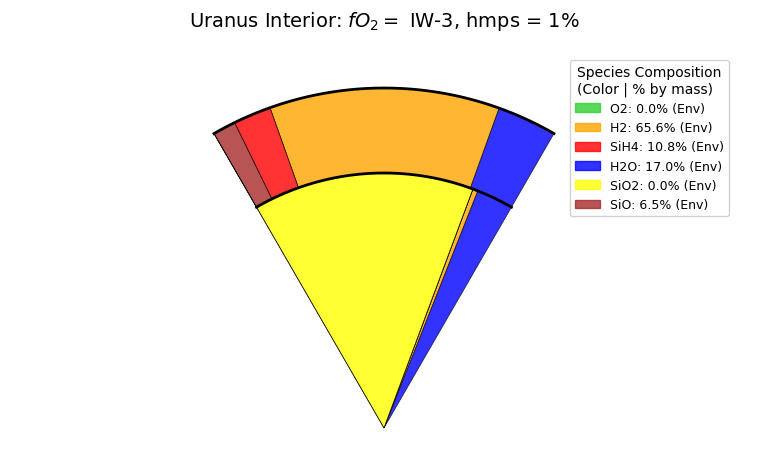

In [32]:
fig, ax = plt.subplots(figsize=(8, 8))
rho_centre = 3000
init_metallicity = 1
mantle_melt_fraction = 1
shift = -3
filename = f"./excel_Uranus_solar_3000K/HOSi/rho{rho_centre}/core_boundary/HOSi_magma_sol_real_{init_metallicity}xsolar_melt{round(mantle_melt_fraction * 100)}_fO2{shift}_2.xlsx"

H2_atmosphere_mass = pd.read_excel(filename, sheet_name="H2_g")["gas_mass"]
H2O_atmosphere_mass = pd.read_excel(filename, sheet_name="H2O_g")["gas_mass"]
#He_atmosphere_mass = pd.read_excel(filename, sheet_name="He_g")["gas_mass"]
O2_atmosphere_mass = pd.read_excel(filename, sheet_name="O2_g")["gas_mass"]
SiH4_atmosphere_mass = pd.read_excel(filename, sheet_name="H4Si_g")["gas_mass"]
SiO_atmosphere_mass = pd.read_excel(filename, sheet_name="OSi_g")["gas_mass"]
tot_atmosphere_mass = pd.read_excel(filename, sheet_name="state")["planet_mass"] - pd.read_excel(filename, sheet_name="state")["mantle_mass"]

H2_mantle_mass = pd.read_excel(filename, sheet_name="H2_g")["dissolved_mass"]
H2O_mantle_mass = pd.read_excel(filename, sheet_name="H2O_g")["dissolved_mass"]
#He_mantle_mass = pd.read_excel(filename, sheet_name="He_g")["dissolved_mass"]
O2_mantle_mass = pd.read_excel(filename, sheet_name="O2_g")["dissolved_mass"]
SiH4_mantle_mass = pd.read_excel(filename, sheet_name="H4Si_g")["dissolved_mass"]
SiO_mantle_mass = pd.read_excel(filename, sheet_name="OSi_g")["dissolved_mass"]
SiO2_mantle_mass = pd.read_excel(filename, sheet_name="O2Si_cd")["total_mass"]
tot_mantle_mass = pd.read_excel(filename, sheet_name="state")["mantle_mass"]

H2_mass = pd.read_excel(filename, sheet_name="H2_g")["total_mass"]
H2O_mass = pd.read_excel(filename, sheet_name="H2O_g")["total_mass"]
#He_mass = pd.read_excel(filename, sheet_name="He_g")["total_mass"]
O2_mass = pd.read_excel(filename, sheet_name="O2_g")["total_mass"]
SiH4_mass = pd.read_excel(filename, sheet_name="H4Si_g")["total_mass"]
SiO_mass = pd.read_excel(filename, sheet_name="OSi_g")["total_mass"]
SiO2_mass = pd.read_excel(filename, sheet_name="O2Si_cd")["total_mass"]
tot_mass = pd.read_excel(filename, sheet_name="state")["planet_mass"]

H2_envelope_perc = H2_atmosphere_mass/tot_atmosphere_mass
H2O_envelope_perc = H2O_atmosphere_mass/tot_atmosphere_mass
#He_envelope_perc = He_atmosphere_mass/tot_atmosphere_mass
O2_envelope_perc = O2_atmosphere_mass/tot_atmosphere_mass
SiH4_envelope_perc = SiH4_atmosphere_mass/tot_atmosphere_mass
SiO_envelope_perc = SiO_atmosphere_mass/tot_atmosphere_mass

H2_mantle_perc = H2_mantle_mass/tot_mantle_mass
H2O_mantle_perc = H2O_mantle_mass/tot_mantle_mass
#He_mantle_perc = He_mantle_mass/tot_mantle_mass
O2_mantle_perc = O2_mantle_mass/tot_mantle_mass
SiH4_mantle_perc = SiH4_mantle_mass/tot_mantle_mass
SiO_mantle_perc = SiO_mantle_mass/tot_mantle_mass
SiO2_mantle_perc = SiO2_mantle_mass/tot_mantle_mass

H2_perc = H2_mass/tot_mass
H2O_perc = H2O_mass/tot_mass
#He_perc = He_mass/tot_mass
O2_perc = O2_mass/tot_mass
SiH4_perc = SiH4_mass/tot_mass
SiO_perc = SiO_mass/tot_mass
SiO2_perc = SiO2_mass/tot_mass

# --- YOUR COMPOSITION DATA ---
# Core composition (mass %, sum = 100)
core_composition = {
    'H2O': H2O_mantle_perc[49]*100,
    'H2': H2_mantle_perc[49]*100,
#    'He': He_mantle_perc[0]*100,
    'SiH4': SiH4_mantle_perc[49]*100,   # adjust these to sum to 100
    'SiO': SiO_mantle_perc[49]*100,
    'SiO2': SiO2_mantle_perc[49]*100,
    'O2': O2_mantle_perc[49]*100
}

envelope_composition = {
    'H2O': H2O_envelope_perc[49]*100,
    'H2': H2_envelope_perc[49]*100,
#    'He': He_envelope_perc[0]*100,
    'SiH4': SiH4_envelope_perc[49]*100,   # adjust these to sum to 100
    'SiO': SiO_envelope_perc[49]*100,
    'O2': O2_envelope_perc[49]*100
}

total_composition = {
    'H2O': H2O_perc[49]*100,
    'H2': H2_perc[49]*100,
#    'He': He_perc[0]*100,
    'SiH4': SiH4_perc[49]*100,   # adjust these to sum to 100
    'SiO': SiO_perc[49]*100,
    'SiO2': SiO2_perc[49]*100,
    'O2': O2_perc[49]*100
}
# Normalize if needed (ensure sums = 100)
def normalize_dict(comp_dict):
    total = sum(comp_dict.values())
    return {k: (v/total)*100 for k, v in comp_dict.items()}

core_comp = normalize_dict(core_composition)
env_comp = normalize_dict(envelope_composition)
total_comp = normalize_dict(total_composition)

# Species colors
species_colors = {
    'SiO2': 'yellow',
    'H2O': 'blue',
    'SiH4': 'red',
    'SiO': 'brown',
    'O2': 'limegreen',
    'H2': 'orange',
    'CO2': 'cyan',
    'CO' : 'magenta',
    'He': 'gray',
    'N2': 'green',
    'CH4': 'purple',
    'NH3': 'pink',
    'MgO': 'darkred',
    'MgH2': 'gold',
    'MgH' :'teal',
    'MgOH' : 'indigo'
    
}

# --- WEDGE PARAMETERS ---
theta1, theta2 = 60, 120 # 20-degree wedge
core_radius = 0.75  # Core extends to 0.2 R_U
total_radius = 1.0

# Convert composition dicts to lists
core_species = list(core_comp.keys())
core_percents = list(core_comp.values())
env_species = list(env_comp.keys())
env_percents = list(env_comp.values())

# --- DRAW CORE AS STACKED VERTICAL SECTORS ---
core_start = 0.0
cumulative = 0.0

for i, (species, percent) in enumerate(zip(core_species, core_percents)):
    angle_width = (theta2 - theta1) * (percent / 100)
    angle_start = theta1 + cumulative * (theta2 - theta1) / 100
    angle_end = angle_start + angle_width
    
    wedge = plt.matplotlib.patches.Wedge(
        (0, 0), core_radius,
        angle_start, angle_end,
        facecolor=species_colors.get(species, 'gray'),
        edgecolor='black',
        linewidth=0.5,
        alpha=0.8
    )
    ax.add_patch(wedge)
    
    # Label inside wedge
    mid_angle = (angle_start + angle_end) / 2
    label_r = core_radius / 2
    label_theta = np.radians(mid_angle)
    x = label_r * np.cos(label_theta) * 1.1
    y = label_r * np.sin(label_theta)
    cumulative += percent

# --- DRAW ENVELOPE AS STACKED VERTICAL SECTORS ---
cumulative = 0.0

for i, (species, percent) in enumerate(zip(env_species, env_percents)):
    angle_width = (theta2 - theta1) * (percent / 100)
    angle_start = theta1 + cumulative * (theta2 - theta1) / 100
    angle_end = angle_start + angle_width
    
    annulus = plt.matplotlib.patches.Wedge(
        (0, 0), total_radius,
        angle_start, angle_end,
        width=total_radius - core_radius,
        facecolor=species_colors.get(species, 'gray'),
        edgecolor='black',
        linewidth=0.5,
        alpha=0.8
    )
    ax.add_patch(annulus)
    
    # Label inside wedge
    mid_angle = (angle_start + angle_end) / 2
    label_r = (core_radius + total_radius) / 2
    label_theta = np.radians(mid_angle)
    x = label_r * np.cos(label_theta) * 1.1
    y = label_r * np.sin(label_theta)
    cumulative += percent

# --- ADD BOUNDARIES ---
theta_line = np.linspace(np.radians(theta1), np.radians(theta2), 100)
x_core = core_radius * np.cos(theta_line)
y_core = core_radius * np.sin(theta_line)
ax.plot(x_core, y_core, 'k-', linewidth=2)

x_outer = total_radius * np.cos(theta_line)
y_outer = total_radius * np.sin(theta_line)
ax.plot(x_outer, y_outer, 'k-', linewidth=2)

# Layer labels
#ax.text(0, core_radius/2, 'CORE', ha='center', va='center', 
#        fontsize=12, fontweight='bold', color='white',
#        bbox=dict(boxstyle="round,pad=0.3", facecolor="black", alpha=0.7))
#ax.text(0, (core_radius + total_radius)/2, 'ENVELOPE', ha='center', va='center', 
#        fontsize=12, fontweight='bold', color='white',
#        bbox=dict(boxstyle="round,pad=0.3", facecolor="black", alpha=0.7))

# --- CREATE LEGEND WITH PERCENTAGES ---
# Combine all unique species with their percentages
legend_entries = []

# Core species in legend
#for species in core_species:
#    percent = core_comp[species]
#    if percent > 0:
#        legend_entries.append(
#            (species_colors[species], 
#             f"{species}: {percent:.1f}% (Core)")
#        )

# Envelope species in legend (only if not already listed)
#for species in env_species:
#    percent = env_comp[species]
#    if percent > 0:
#        legend_entries.append(
#            (species_colors[species], 
#             f"{species}: {percent:.1f}% (Env)")
#        )

# Species that appear in both
for species in set(core_species) or set(env_species):
    core_p = core_comp.get(species, 0)
    env_p = env_comp.get(species, 0)
    tot_p = total_comp.get(species, 0)
    if core_p > 0 or env_p > 0:
        legend_entries.append(
            (species_colors[species], 
             f"{species}: {env_p:.1f}% (Env)")
        )

# Create legend patches
legend_patches = [
    Patch(color=color, label=label, alpha=0.8)
    for color, label in legend_entries
]

# Add legend
ax.legend(handles=legend_patches, 
          loc='upper left', 
          bbox_to_anchor=(0.74, 1),
          title="Species Composition\n(Color | % by mass)",
          fontsize=9,
          title_fontsize=10,
          framealpha=0.9)

# --- FINISH PLOT ---
ax.set_xlim(-1.1, 1.1)  # Extra space for legend
ax.set_ylim(-0.1, 1.1)
ax.set_aspect('equal')
ax.axis('off')
ax.set_title(r'Uranus Interior: $fO_2 =$ IW-3, hmps = 1%', 
             fontsize=14, pad=20)

plt.tight_layout()
plt.show()

Text(-0.02, 0.5, 'Gas number density (mol)')

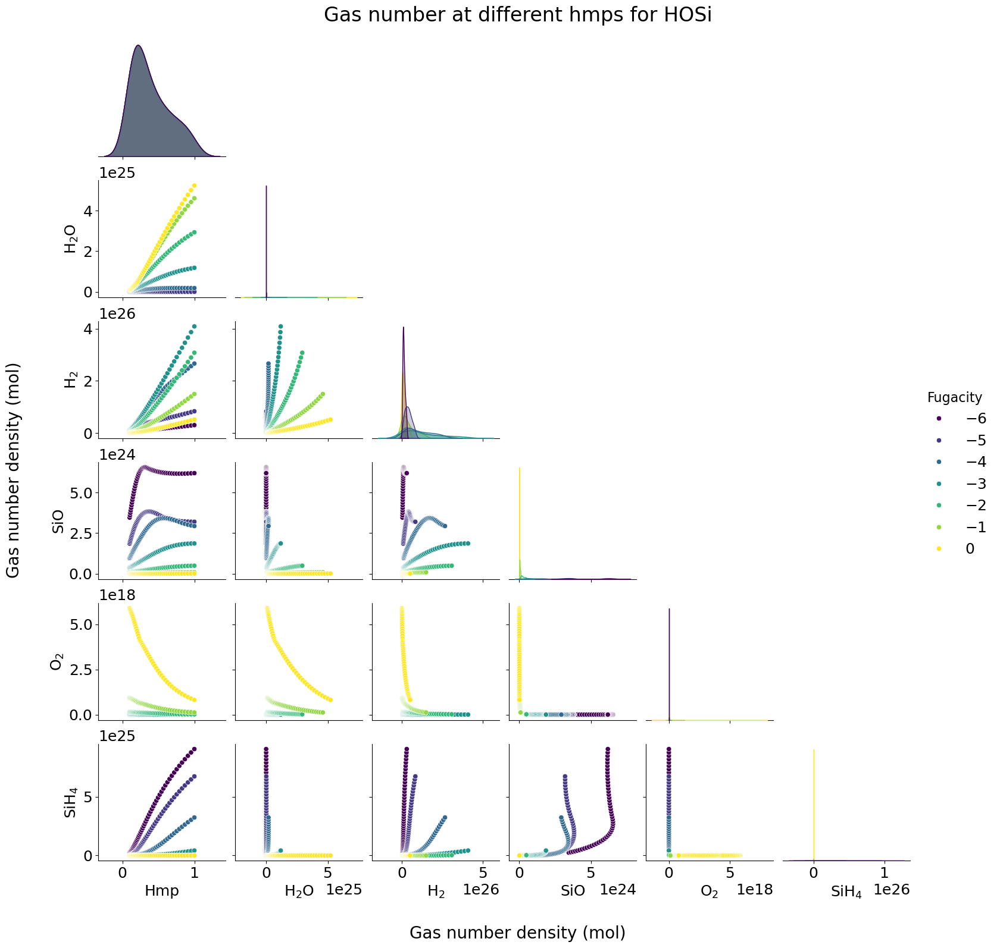

In [25]:
g = sns.pairplot(
    df_gas_number,
    vars=["Hmp",r"H$_2$O", r"H$_2$", "SiO", r"O$_2$",r"SiH$_4$"],
    hue="Fugacity",
    corner=True,
    palette="viridis"
)

new_labels = ["HMPS", "H2O atmospheric mass", "H2 atmospheric mass", "SiO atmospheric mass", "O2 atmospheric mass", "SiH4 atmospheric mass"]
g.fig.suptitle("Gas number at different hmps for HOSi", y=1.02, fontsize=24)  # overall title
g.fig.text(0.5, -0.02, r"Gas number density (mol)", ha='center', va='center', fontsize=20)
g.fig.text(-0.02, 0.5, r"Gas number density (mol)", ha='center', va='center', rotation=90, fontsize=20)

Text(-0.02, 0.5, 'Partial Pressures (Bar)')

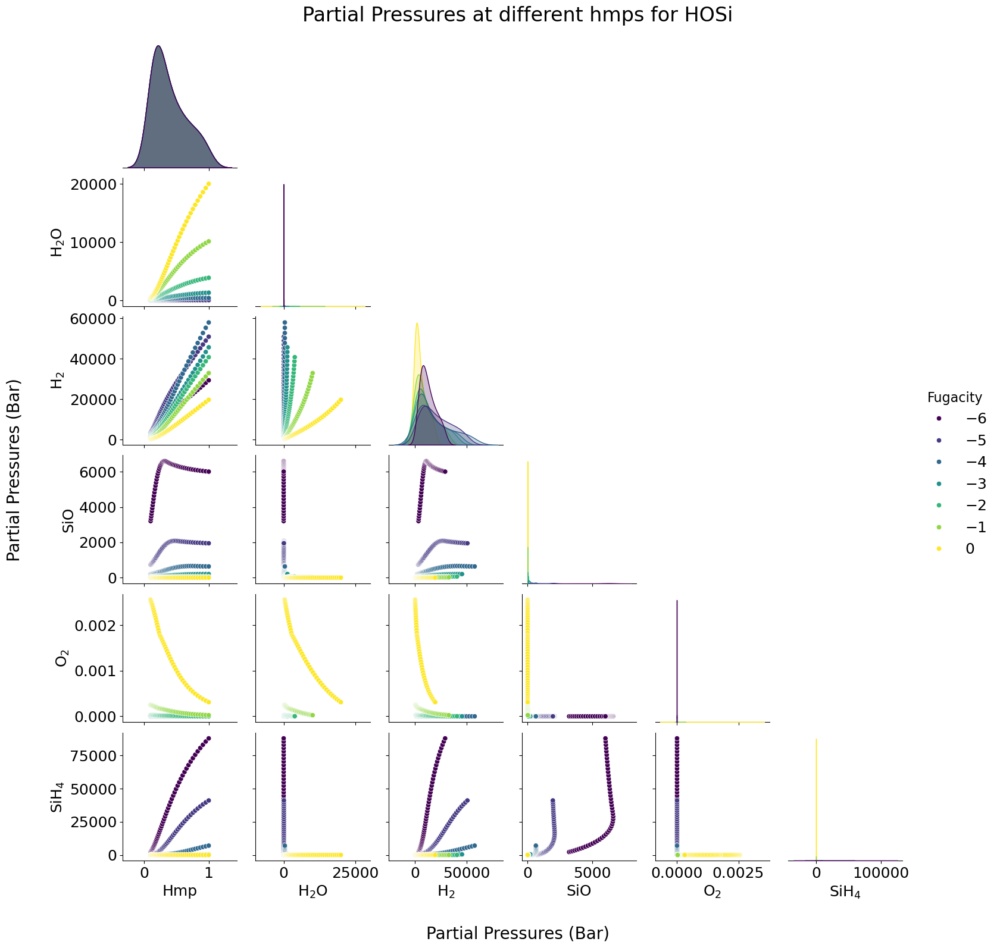

In [30]:
g = sns.pairplot(
    df_pressures,
    vars=["Hmp",r"H$_2$O", r"H$_2$", "SiO", r"O$_2$",r"SiH$_4$"],
    hue="Fugacity",
    corner=True,
    palette="viridis"
)

new_labels = ["HMPS", "H2O atmospheric mass", "H2 atmospheric mass", "SiO atmospheric mass", "O2 atmospheric mass", "SiH4 atmospheric mass"]
g.fig.suptitle("Partial Pressures at different hmps for HOSi", y=1.02, fontsize=24)  # overall title
g.fig.text(0.5, -0.02, r"Partial Pressures (Bar)", ha='center', va='center', fontsize=20)
g.fig.text(-0.02, 0.5, r"Partial Pressures (Bar)", ha='center', va='center', rotation=90, fontsize=20)

Text(0.5, 1.02, 'Gas mass at different hmps for HOSi')

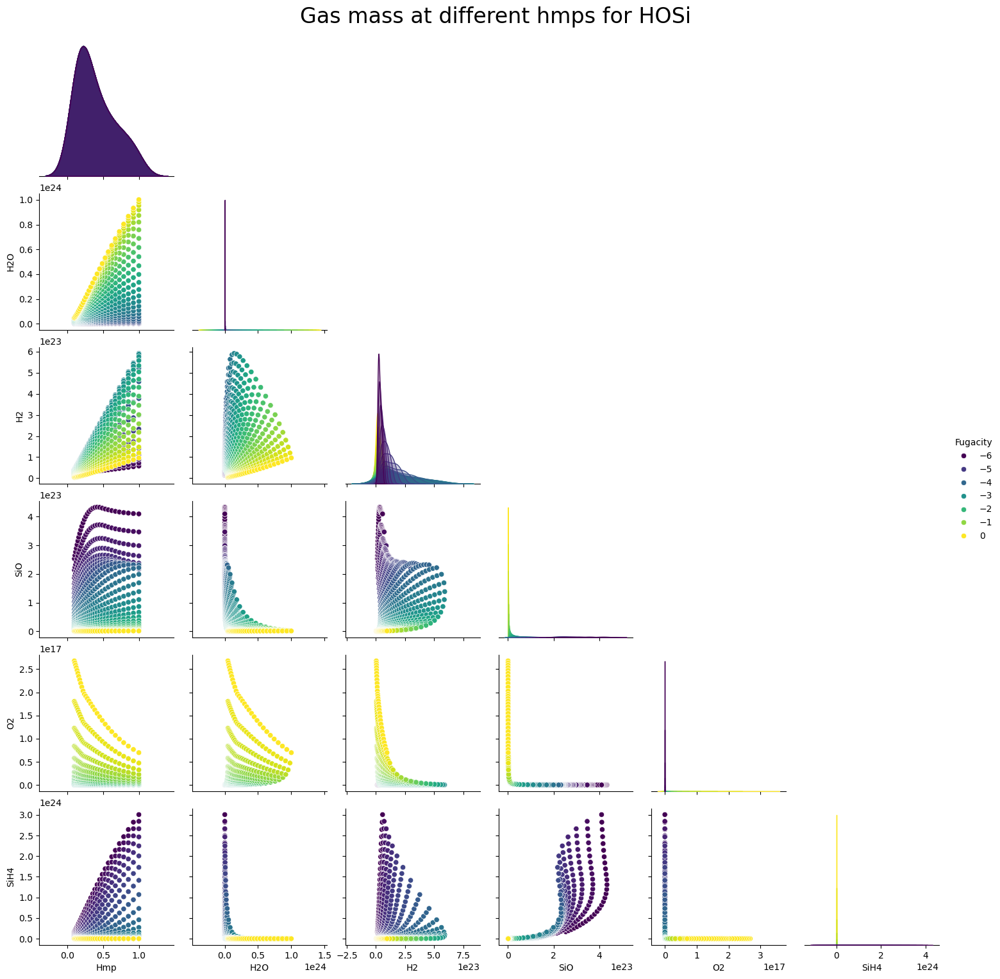

In [41]:
g = sns.pairplot(
    df_gas_mass,
    vars=["Hmp","H2O", "H2", "SiO", "O2","SiH4"],
    hue="Fugacity",
    corner=True,
    palette="viridis"
)

new_labels = ["HMPS", "H2O atmospheric mass", "H2 atmospheric mass", "SiO atmospheric mass", "O2 atmospheric mass", "SiH4 atmospheric mass"]
g.fig.suptitle("Gas mass at different hmps for HOSi", y=1.02, fontsize=24)  # overall title

Text(0.5, 1.02, 'Gas number density at different hmps for HOSi')

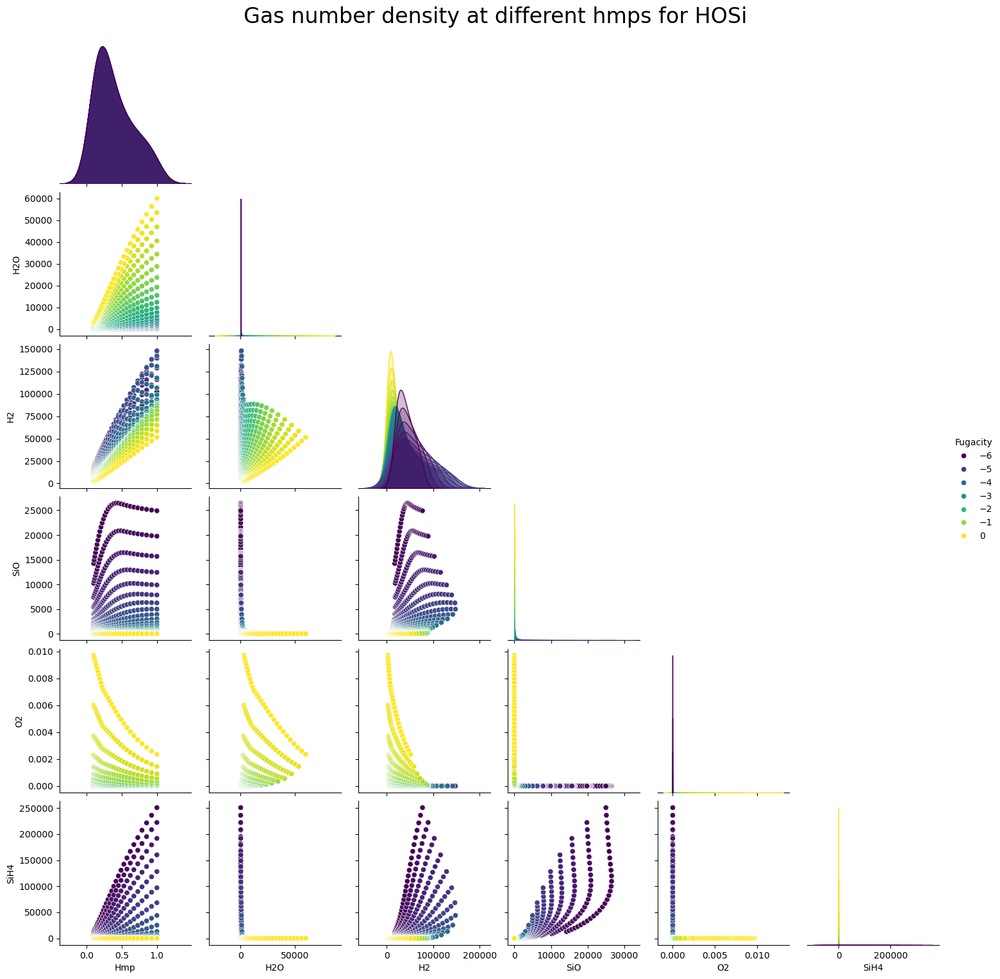

In [42]:
g = sns.pairplot(
    df_gas_number_density,
    vars=["Hmp","H2O", "H2", "SiO", "O2","SiH4"],
    hue="Fugacity",
    corner=True,
    palette="viridis"
)

new_labels = ["HMPS", "H2O atmospheric mass", "H2 atmospheric mass", "SiO atmospheric mass", "O2 atmospheric mass", "SiH4 atmospheric mass"]
g.fig.suptitle("Gas number density at different hmps for HOSi", y=1.02, fontsize=24)  # overall title

Text(0.5, 1.02, 'Dissolved number at different hmps for HOSi')

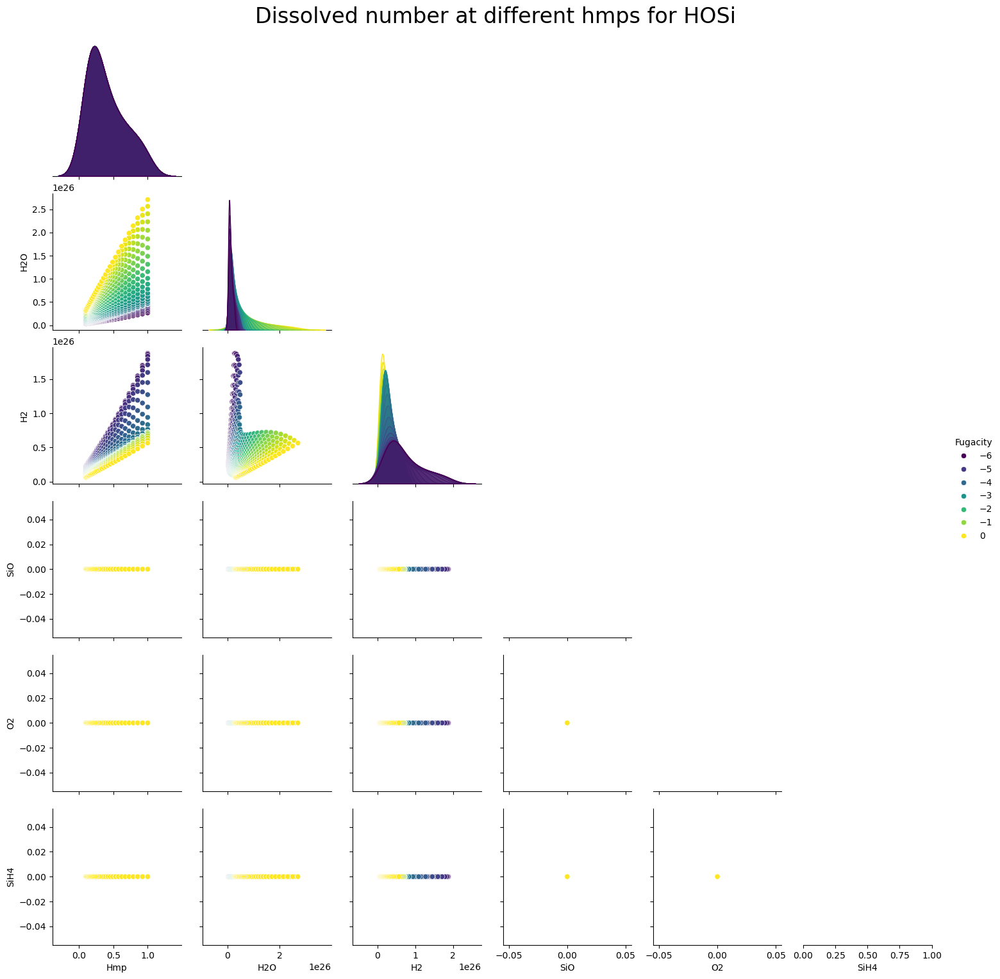

In [44]:
g = sns.pairplot(
    df_dissolved_number,
    vars=["Hmp","H2O", "H2", "SiO", "O2","SiH4"],
    hue="Fugacity",
    corner=True,
    palette="viridis"
)

new_labels = ["HMPS", "H2O atmospheric mass", "H2 atmospheric mass", "SiO atmospheric mass", "O2 atmospheric mass", "SiH4 atmospheric mass"]
g.fig.suptitle("Dissolved number at different hmps for HOSi", y=1.02, fontsize=24)  # overall title

Text(0.5, 1.02, 'Dissolved mass at different hmps for HOSi')

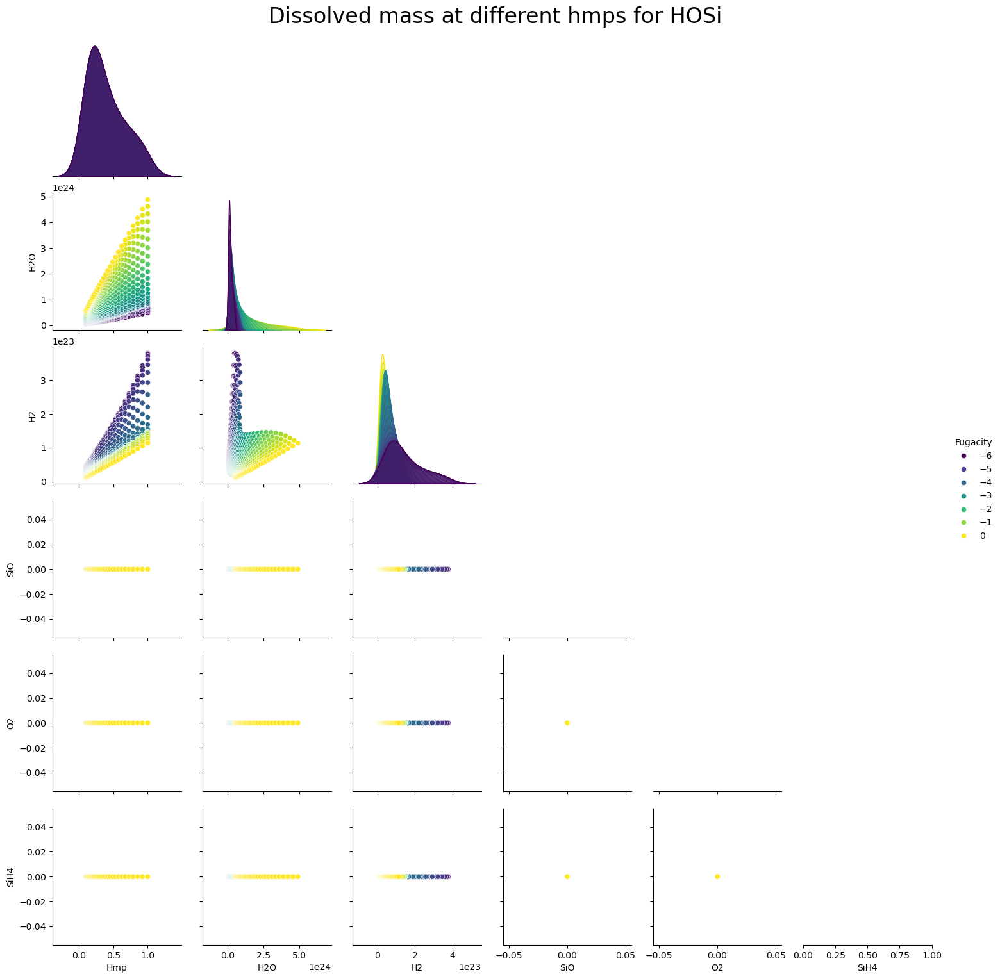

In [45]:
g = sns.pairplot(
    df_dissolved_mass,
    vars=["Hmp","H2O", "H2", "SiO", "O2","SiH4"],
    hue="Fugacity",
    corner=True,
    palette="viridis"
)

new_labels = ["HMPS", "H2O atmospheric mass", "H2 atmospheric mass", "SiO atmospheric mass", "O2 atmospheric mass", "SiH4 atmospheric mass"]
g.fig.suptitle("Dissolved mass at different hmps for HOSi", y=1.02, fontsize=24)  # overall title

Text(0.5, 1.02, 'Total mass at different hmps for HOSi')

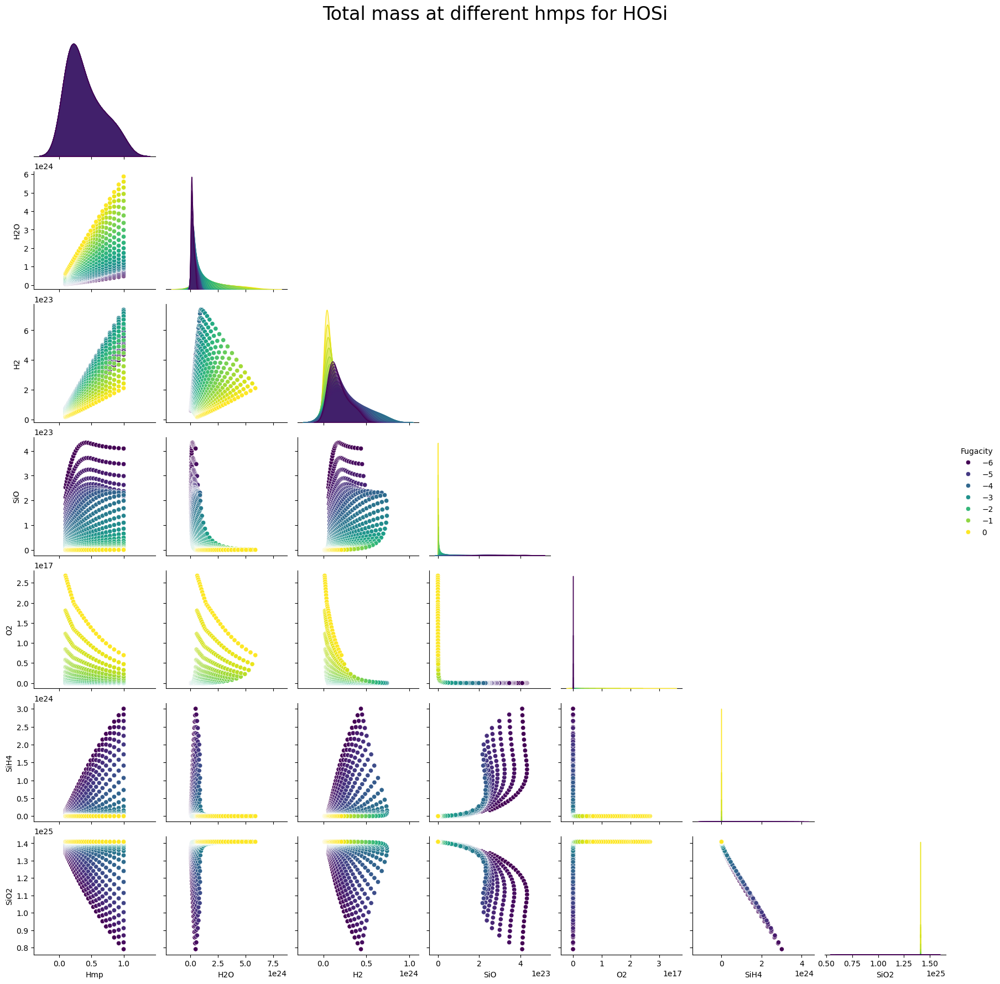

In [35]:
g = sns.pairplot(
    df_total_mass,
    vars=["Hmp","H2O", "H2", "SiO", "O2","SiH4", "SiO2"],
    hue="Fugacity",
    corner=True,
    palette="viridis"
)

new_labels = ["HMPS", "H2O atmospheric mass", "H2 atmospheric mass", "SiO atmospheric mass", "O2 atmospheric mass", "SiH4 atmospheric mass"]
g.fig.suptitle("Total mass at different hmps for HOSi", y=1.02, fontsize=24)  # overall title

Text(0.5, 1.02, 'Total number at different hmps for HOSi')

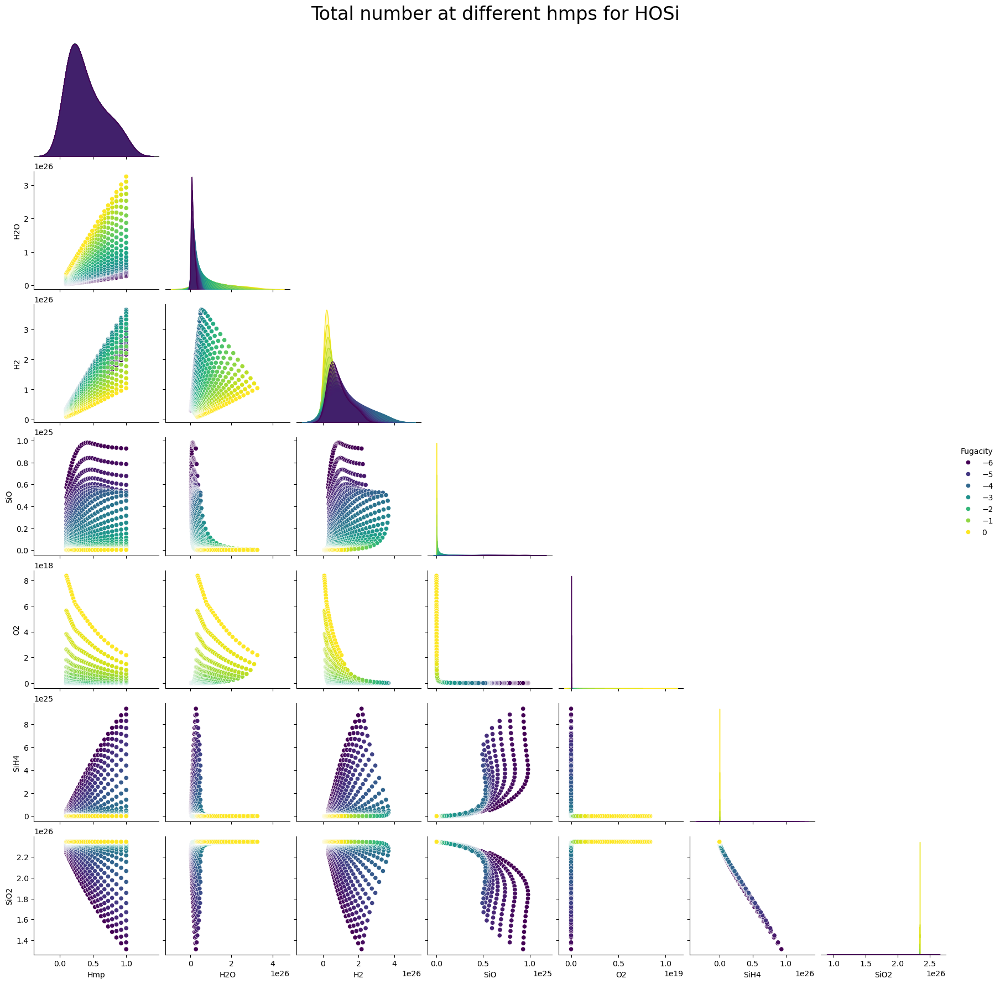

In [74]:
g = sns.pairplot(
    df_total_number,
    vars=["Hmp","H2O", "H2", "SiO", "O2","SiH4", "SiO2"],
    hue="Fugacity",
    corner=True,
    palette="viridis"
)

new_labels = ["HMPS", "H2O atmospheric mass", "H2 atmospheric mass", "SiO atmospheric mass", "O2 atmospheric mass", "SiH4 atmospheric mass"]
g.fig.suptitle("Total number at different hmps for HOSi", y=1.02, fontsize=24)  # overall title

# HHeCNOSi cornerplots

In [31]:
rows_gas_number = []
rows_gas_mass = []
rows_gas_number_density = []
rows_dissolved_number = []
rows_dissolved_mass = []
rows_total_number = []
rows_total_mass = []

rho_centre = 3000
init_metallicity = 1
mantle_melt_fraction = 1
for fO2_log10_shift in fO2_log10_shifts:
    shift = f"{fO2_log10_shift:.2g}"
    filename = f"./excel_Uranus_solar_3000K/HHeCNOSi/rho{rho_centre}/core_boundary/HHeCNOSi_magma_sol_real_{init_metallicity}xsolar_melt{round(mantle_melt_fraction * 100)}_fO2{shift}_2.xlsx"

    #gas number 
    H2O_gas_number = pd.read_excel(filename, sheet_name="H2O_g")["gas_number"]
    H2_gas_number = pd.read_excel(filename, sheet_name="H2_g")["gas_number"]
    O2_gas_number = pd.read_excel(filename, sheet_name="O2_g")["gas_number"]
    SiO_gas_number = pd.read_excel(filename, sheet_name="OSi_g")["gas_number"]
    SiH4_gas_number = pd.read_excel(filename, sheet_name="H4Si_g")["gas_number"]
    CO2_gas_number = pd.read_excel(filename, sheet_name="CO2_g")["gas_number"]
    CO_gas_number = pd.read_excel(filename, sheet_name="CO_g")["gas_number"]
    CH4_gas_number = pd.read_excel(filename, sheet_name="CH4_g")["gas_number"]
    N2_gas_number = pd.read_excel(filename, sheet_name="N2_g")["gas_number"]
    NH3_gas_number = pd.read_excel(filename, sheet_name="H3N_g")["gas_number"]
    He_gas_number = pd.read_excel(filename, sheet_name="He_g")["gas_number"]
    for i in range(len(hmps)):        
        rows_gas_number.append({
            "Fugacity": float(shift),
            "Hmp": hmps[i],
            r"H$_2$O": H2O_gas_number[i],
            "SiO": SiO_gas_number[i],
            r"H$_2$": H2_gas_number[i],
            r"O$_2$": O2_gas_number[i],
            r"SiH$_4$": SiH4_gas_number[i],
            r"CO$_2$": CO2_gas_number[i],
            "CO": CO_gas_number[i],
            r"CH$_4$": CH4_gas_number[i],
            r"N$_2$": N2_gas_number[i],
            r"NH$_3$": NH3_gas_number[i],
            "He": He_gas_number[i]
        })

    #gas_mass
    H2O_gas_mass = pd.read_excel(filename, sheet_name="H2O_g")["gas_mass"]
    H2_gas_mass = pd.read_excel(filename, sheet_name="H2_g")["gas_mass"]
    O2_gas_mass = pd.read_excel(filename, sheet_name="O2_g")["gas_mass"]
    SiO_gas_mass = pd.read_excel(filename, sheet_name="OSi_g")["gas_mass"]
    SiH4_gas_mass = pd.read_excel(filename, sheet_name="H4Si_g")["gas_mass"]
    CO2_gas_mass = pd.read_excel(filename, sheet_name="CO2_g")["gas_mass"]
    CO_gas_mass = pd.read_excel(filename, sheet_name="CO_g")["gas_mass"]
    CH4_gas_mass = pd.read_excel(filename, sheet_name="CH4_g")["gas_mass"]
    N2_gas_mass = pd.read_excel(filename, sheet_name="N2_g")["gas_mass"]
    NH3_gas_mass = pd.read_excel(filename, sheet_name="H3N_g")["gas_mass"]
    He_gas_mass = pd.read_excel(filename, sheet_name="He_g")["gas_mass"]

    for i in range(len(hmps)):        
        rows_gas_mass.append({
            "Fugacity": float(shift),
            "Hmp": hmps[i],
            r"H$_2$O": H2O_gas_mass[i],
            "SiO": SiO_gas_mass[i],
            r"H$_2$": H2_gas_mass[i],
            r"O$_2$": O2_gas_mass[i],
            r"SiH$_4$": SiH4_gas_mass[i],
            r"CO$_2$": CO2_gas_mass[i],
            "CO": CO_gas_mass[i],
            r"CH$_4$": CH4_gas_mass[i],
            r"N$_2$": N2_gas_mass[i],
            r"NH$_3$": NH3_gas_mass[i],
            "He": He_gas_mass[i]

        })

    #gas_number_density
    H2O_gas_number_density = pd.read_excel(filename, sheet_name="H2O_g")["gas_number_density"]
    H2_gas_number_density = pd.read_excel(filename, sheet_name="H2_g")["gas_number_density"]
    O2_gas_number_density = pd.read_excel(filename, sheet_name="O2_g")["gas_number_density"]
    SiO_gas_number_density = pd.read_excel(filename, sheet_name="OSi_g")["gas_number_density"]
    SiH4_gas_number_density = pd.read_excel(filename, sheet_name="H4Si_g")["gas_number_density"]
    CO2_gas_number_density = pd.read_excel(filename, sheet_name="CO2_g")["gas_number_density"]
    CO_gas_number_density = pd.read_excel(filename, sheet_name="CO_g")["gas_number_density"]
    CH4_gas_number_density = pd.read_excel(filename, sheet_name="CH4_g")["gas_number_density"]
    N2_gas_number_density = pd.read_excel(filename, sheet_name="N2_g")["gas_number_density"]
    NH3_gas_number_density = pd.read_excel(filename, sheet_name="H3N_g")["gas_number_density"]
    He_gas_number_density = pd.read_excel(filename, sheet_name="He_g")["gas_number_density"]

    for i in range(len(hmps)):        
        rows_gas_number_density.append({
            "Fugacity": float(shift),
            "Hmp": hmps[i],
            r"H$_2$O": H2O_gas_number_density[i],
            "SiO": SiO_gas_number_density[i],
            r"H$_2$": H2_gas_number_density[i],
            r"O$_2$": O2_gas_number_density[i],
            r"SiH$_4$": SiH4_gas_number_density[i],
            r"CO$_2$": CO2_gas_number_density[i],
            "CO": CO_gas_number_density[i],
            r"CH$_4$": CH4_gas_number_density[i],
            r"N$_2$": N2_gas_number_density[i],
            r"NH$_3$": NH3_gas_number_density[i],
            "He": He_gas_number_density[i]
        })

    #dissolved_number
    H2O_dissolved_number = pd.read_excel(filename, sheet_name="H2O_g")["dissolved_number"]
    H2_dissolved_number = pd.read_excel(filename, sheet_name="H2_g")["dissolved_number"]
    O2_dissolved_number = pd.read_excel(filename, sheet_name="O2_g")["dissolved_number"]
    SiO_dissolved_number = pd.read_excel(filename, sheet_name="OSi_g")["dissolved_number"]
    SiH4_dissolved_number = pd.read_excel(filename, sheet_name="H4Si_g")["dissolved_number"]
    CO2_dissolved_number = pd.read_excel(filename, sheet_name="CO2_g")["dissolved_number"]
    CO_dissolved_number = pd.read_excel(filename, sheet_name="CO_g")["dissolved_number"]
    CH4_dissolved_number = pd.read_excel(filename, sheet_name="CH4_g")["dissolved_number"]
    N2_dissolved_number = pd.read_excel(filename, sheet_name="N2_g")["dissolved_number"]
    NH3_dissolved_number = pd.read_excel(filename, sheet_name="H3N_g")["dissolved_number"]
    He_dissolved_number = pd.read_excel(filename, sheet_name="He_g")["dissolved_number"]

    for i in range(len(hmps)):        
        rows_dissolved_number.append({
            "Fugacity": float(shift),
            "Hmp": hmps[i],
            r"H$_2$O": H2O_dissolved_number[i],
            "SiO": SiO_dissolved_number[i],
            r"H$_2$": H2_dissolved_number[i],
            r"O$_2$": O2_dissolved_number[i],
            r"SiH$_4$": SiH4_dissolved_number[i],
            r"CO$_2$": CO2_dissolved_number[i],
            "CO": CO_dissolved_number[i],
            r"CH$_4$": CH4_dissolved_number[i],
            r"N$_2$": N2_dissolved_number[i],
            r"NH$_3$": NH3_dissolved_number[i],
            "He": He_dissolved_number[i]

        })

    #dissolved_mass
    H2O_dissolved_mass = pd.read_excel(filename, sheet_name="H2O_g")["dissolved_mass"]
    H2_dissolved_mass = pd.read_excel(filename, sheet_name="H2_g")["dissolved_mass"]
    O2_dissolved_mass = pd.read_excel(filename, sheet_name="O2_g")["dissolved_mass"]
    SiO_dissolved_mass = pd.read_excel(filename, sheet_name="OSi_g")["dissolved_mass"]
    SiH4_dissolved_mass = pd.read_excel(filename, sheet_name="H4Si_g")["dissolved_mass"]
    CO2_dissolved_mass = pd.read_excel(filename, sheet_name="CO2_g")["dissolved_mass"]
    CO_dissolved_mass = pd.read_excel(filename, sheet_name="CO_g")["dissolved_mass"]
    CH4_dissolved_mass = pd.read_excel(filename, sheet_name="CH4_g")["dissolved_mass"]
    N2_dissolved_mass = pd.read_excel(filename, sheet_name="N2_g")["dissolved_mass"]
    NH3_dissolved_mass = pd.read_excel(filename, sheet_name="H3N_g")["dissolved_mass"]
    He_dissolved_mass = pd.read_excel(filename, sheet_name="He_g")["dissolved_mass"]

    for i in range(len(hmps)):        
        rows_dissolved_mass.append({
            "Fugacity": float(shift),
            "Hmp": hmps[i],
            r"H$_2$O": H2O_dissolved_mass[i],
            "SiO": SiO_dissolved_mass[i],
            r"H$_2$": H2_dissolved_mass[i],
            r"O$_2$": O2_dissolved_mass[i],
            r"SiH$_4$": SiH4_dissolved_mass[i],
            r"CO$_2$": CO2_dissolved_mass[i],
            "CO": CO_dissolved_mass[i],
            r"CH$_4$": CH4_dissolved_mass[i],
            r"N$_2$": N2_dissolved_mass[i],
            r"NH$_3$": NH3_dissolved_mass[i],
            "He": He_dissolved_mass[i]

        })

    #total mass
    
    H2O_mass = pd.read_excel(filename, sheet_name="H2O_g")["total_mass"]
    H2_mass = pd.read_excel(filename, sheet_name="H2_g")["total_mass"]
    O2_mass = pd.read_excel(filename, sheet_name="O2_g")["total_mass"]
    SiO_mass = pd.read_excel(filename, sheet_name="OSi_g")["total_mass"]
    SiH4_mass = pd.read_excel(filename, sheet_name="H4Si_g")["total_mass"]
    O2Si_mass = pd.read_excel(filename, sheet_name="O2Si_cd")["total_mass"]
    CO2_total_mass = pd.read_excel(filename, sheet_name="CO2_g")["total_mass"]
    CO_total_mass = pd.read_excel(filename, sheet_name="CO_g")["total_mass"]
    CH4_total_mass = pd.read_excel(filename, sheet_name="CH4_g")["total_mass"]
    N2_total_mass = pd.read_excel(filename, sheet_name="N2_g")["total_mass"]
    NH3_total_mass = pd.read_excel(filename, sheet_name="H3N_g")["total_mass"]
    He_total_mass = pd.read_excel(filename, sheet_name="He_g")["total_mass"]

    for i in range(len(hmps)):        
        rows_total_mass.append({
            "Fugacity": float(shift),
            "Hmp": hmps[i],
            r"H$_2$O": H2O_mass[i],
            "SiO": SiO_mass[i],
            r"H$_2$": H2_mass[i],
            r"O$_2$": O2_mass[i],
            r"SiH$_4$": SiH4_mass[i],
            r"SiO$_2$": O2Si_mass[i],
            r"CO$_2$": CO2_total_mass[i],
            "CO": CO_total_mass[i],
            r"CH$_4$": CH4_total_mass[i],
            r"N$_2$": N2_total_mass[i],
            r"NH$_3$": NH3_total_mass[i],
            "He": He_total_mass[i]
        })

    #total number
    
    H2O_number = pd.read_excel(filename, sheet_name="H2O_g")["total_number"]
    H2_number = pd.read_excel(filename, sheet_name="H2_g")["total_number"]
    O2_number = pd.read_excel(filename, sheet_name="O2_g")["total_number"]
    SiO_number = pd.read_excel(filename, sheet_name="OSi_g")["total_number"]
    SiH4_number = pd.read_excel(filename, sheet_name="H4Si_g")["total_number"]
    O2Si_number = pd.read_excel(filename, sheet_name="O2Si_cd")["total_number"]
    CO2_total_number = pd.read_excel(filename, sheet_name="CO2_g")["total_number"]
    CO_total_number = pd.read_excel(filename, sheet_name="CO_g")["total_number"]
    CH4_total_number = pd.read_excel(filename, sheet_name="CH4_g")["total_number"]
    N2_total_number = pd.read_excel(filename, sheet_name="N2_g")["total_number"]
    NH3_total_number = pd.read_excel(filename, sheet_name="H3N_g")["total_number"]
    He_total_number = pd.read_excel(filename, sheet_name="He_g")["total_number"]

    for i in range(len(hmps)):        
        rows_total_number.append({
            "Fugacity": float(shift),
            "Hmp": hmps[i],
            r"H$_2$O": H2O_number[i],
            "SiO": SiO_number[i],
            r"H$_2$": H2_number[i],
            r"O$_2$": O2_number[i],
            r"SiH$_4$": SiH4_number[i],
            r"SiO$_2$": O2Si_number[i],
            r"CO$_2$": CO2_total_number[i],
            "CO": CO_total_number[i],
            r"CH$_4$": CH4_total_number[i],
            r"N$_2$": N2_total_number[i],
            r"NH$_3$": NH3_total_number[i],
            "He": He_total_number[i]

        })

df_gas_numberHHeCNOSi  = pd.DataFrame(rows_gas_number)
df_gas_massHHeCNOSi = pd.DataFrame(rows_gas_mass)
df_gas_number_densityHHeCNOSi = pd.DataFrame(rows_gas_number_density)
df_dissolved_numberHHeCNOSi = pd.DataFrame(rows_dissolved_number)
df_dissolved_massHHeCNOSi = pd.DataFrame(rows_dissolved_mass)
df_total_massHHeCNOSi = pd.DataFrame(rows_total_mass)
df_total_numberHHeCNOSi = pd.DataFrame(rows_total_number)


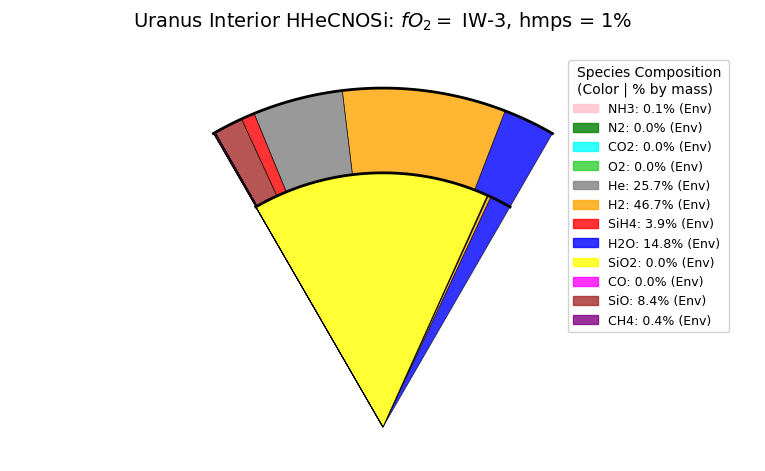

In [36]:
fig, ax = plt.subplots(figsize=(8, 8))

rho_centre = 3000
init_metallicity = 1
mantle_melt_fraction = 1
shift = -3
filename = f"./excel_Uranus_solar_3000K/HHeCNOSi/rho{rho_centre}/core_boundary/HHeCNOSi_magma_sol_real_{init_metallicity}xsolar_melt{round(mantle_melt_fraction * 100)}_fO2{shift}_2.xlsx"
H2O_atmosphere_mass = pd.read_excel(filename, sheet_name="H2O_g")["gas_mass"]
H2_atmosphere_mass = pd.read_excel(filename, sheet_name="H2_g")["gas_mass"]
O2_atmosphere_mass = pd.read_excel(filename, sheet_name="O2_g")["gas_mass"]
SiO_atmosphere_mass = pd.read_excel(filename, sheet_name="OSi_g")["gas_mass"]
SiH4_atmosphere_mass = pd.read_excel(filename, sheet_name="H4Si_g")["gas_mass"]
He_atmosphere_mass = pd.read_excel(filename, sheet_name="He_g")["gas_mass"]
CO2_atmosphere_mass = pd.read_excel(filename, sheet_name="CO2_g")["gas_mass"]
CO_atmosphere_mass = pd.read_excel(filename, sheet_name="CO_g")["gas_mass"]
CH4_atmosphere_mass = pd.read_excel(filename, sheet_name="CH4_g")["gas_mass"]
N2_atmosphere_mass = pd.read_excel(filename, sheet_name="N2_g")["gas_mass"]
NH3_atmosphere_mass = pd.read_excel(filename, sheet_name="H3N_g")["gas_mass"]
tot_atmosphere_mass = pd.read_excel(filename, sheet_name="state")["planet_mass"] - pd.read_excel(filename, sheet_name="state")["mantle_mass"]

H2O_mantle_mass = pd.read_excel(filename, sheet_name="H2O_g")["dissolved_mass"]
H2_mantle_mass = pd.read_excel(filename, sheet_name="H2_g")["dissolved_mass"]
O2_mantle_mass = pd.read_excel(filename, sheet_name="O2_g")["dissolved_mass"]
SiO_mantle_mass = pd.read_excel(filename, sheet_name="OSi_g")["dissolved_mass"]
SiH4_mantle_mass = pd.read_excel(filename, sheet_name="H4Si_g")["dissolved_mass"]
He_mantle_mass = pd.read_excel(filename, sheet_name="He_g")["dissolved_mass"]
CO2_mantle_mass = pd.read_excel(filename, sheet_name="CO2_g")["dissolved_mass"]
CO_mantle_mass = pd.read_excel(filename, sheet_name="CO_g")["dissolved_mass"]
CH4_mantle_mass = pd.read_excel(filename, sheet_name="CH4_g")["dissolved_mass"]
N2_mantle_mass = pd.read_excel(filename, sheet_name="N2_g")["dissolved_mass"]
NH3_mantle_mass = pd.read_excel(filename, sheet_name="H3N_g")["dissolved_mass"]
SiO2_mantle_mass = pd.read_excel(filename, sheet_name="O2Si_cd")["total_mass"]
tot_mantle_mass = pd.read_excel(filename, sheet_name="state")["mantle_mass"]

H2O_mass = pd.read_excel(filename, sheet_name="H2O_g")["total_mass"]
H2_mass = pd.read_excel(filename, sheet_name="H2_g")["total_mass"]
O2_mass = pd.read_excel(filename, sheet_name="O2_g")["total_mass"]
SiO_mass = pd.read_excel(filename, sheet_name="OSi_g")["total_mass"]
SiH4_mass = pd.read_excel(filename, sheet_name="H4Si_g")["total_mass"]
He_mass = pd.read_excel(filename, sheet_name="He_g")["total_mass"]
CO2_mass = pd.read_excel(filename, sheet_name="CO2_g")["total_mass"]
CO_mass = pd.read_excel(filename, sheet_name="CO_g")["total_mass"]
CH4_mass = pd.read_excel(filename, sheet_name="CH4_g")["total_mass"]
N2_mass = pd.read_excel(filename, sheet_name="N2_g")["total_mass"]
NH3_mass = pd.read_excel(filename, sheet_name="H3N_g")["total_mass"]
SiO2_mass = pd.read_excel(filename, sheet_name="O2Si_cd")["total_mass"]

tot_mass = pd.read_excel(filename, sheet_name="state")["planet_mass"]

H2O_envelope_perc = H2O_atmosphere_mass/tot_atmosphere_mass
H2_envelope_perc = H2_atmosphere_mass/tot_atmosphere_mass
O2_envelope_perc = O2_atmosphere_mass/tot_atmosphere_mass
SiO_envelope_perc = SiO_atmosphere_mass/tot_atmosphere_mass
SiH4_envelope_perc = SiH4_atmosphere_mass/tot_atmosphere_mass
He_envelope_perc = He_atmosphere_mass/tot_atmosphere_mass
CO2_envelope_perc = CO2_atmosphere_mass/tot_atmosphere_mass
CO_envelope_perc = CO_atmosphere_mass/tot_atmosphere_mass
CH4_envelope_perc = CH4_atmosphere_mass/tot_atmosphere_mass
N2_envelope_perc = N2_atmosphere_mass/tot_atmosphere_mass
NH3_envelope_perc = NH3_atmosphere_mass/tot_atmosphere_mass

H2O_mantle_perc = H2O_mantle_mass/tot_mantle_mass
H2_mantle_perc = H2_mantle_mass/tot_mantle_mass
O2_mantle_perc = O2_mantle_mass/tot_mantle_mass
SiO_mantle_perc = SiO_mantle_mass/tot_mantle_mass
SiH4_mantle_perc = SiH4_mantle_mass/tot_mantle_mass
He_mantle_perc = He_mantle_mass/tot_mantle_mass
CO2_mantle_perc = CO2_mantle_mass/tot_mantle_mass
CO_mantle_perc = CO_mantle_mass/tot_mantle_mass
CH4_mantle_perc = CH4_mantle_mass/tot_mantle_mass
N2_mantle_perc = N2_mantle_mass/tot_mantle_mass
NH3_mantle_perc = NH3_mantle_mass/tot_mantle_mass
SiO2_mantle_perc = SiO2_mantle_mass/tot_mantle_mass


H2O_perc = H2O_mass/tot_mass
H2_perc = H2_mass/tot_mass
O2_perc = O2_mass/tot_mass
SiO_perc = SiO_mass/tot_mass
SiH4_perc = SiH4_mass/tot_mass
He_perc = He_mass/tot_mass
CO2_perc = CO2_mass/tot_mass
CO_perc = CO_mass/tot_mass
CH4_perc = CH4_mass/tot_mass
N2_perc = N2_mass/tot_mass
NH3_perc = NH3_mass/tot_mass
SiO2_perc = SiO2_mass/tot_mass


# Core composition
core_composition = {
    'H2O': H2O_mantle_perc[49]*100,
    'H2': H2_mantle_perc[49]*100,
    'He': He_mantle_perc[49]*100,
    'SiH4': SiH4_mantle_perc[49]*100,   # adjust these to sum to 100
    'SiO': SiO_mantle_perc[49]*100,
    'SiO2': SiO2_mantle_perc[49]*100,
    'O2': O2_mantle_perc[49]*100,
    'CO2': CO2_mantle_perc[49]*100,
    'CO': CO_mantle_perc[49]*100,
    'CH4': CH4_mantle_perc[49]*100,
    'N2': N2_mantle_perc[49]*100,
    'NH3' : NH3_mantle_perc[49]*100
}

# Envelope composition
envelope_composition = {
    'H2O': H2O_envelope_perc[49]*100,
    'H2': H2_envelope_perc[49]*100,
    'He': He_envelope_perc[49]*100,
    'SiH4': SiH4_envelope_perc[49]*100,   # adjust these to sum to 100
    'SiO': SiO_envelope_perc[49]*100,
    'O2': O2_envelope_perc[49]*100,
    'CO2': CO2_envelope_perc[49]*100,
    'CO': CO_envelope_perc[49]*100,
    'CH4': CH4_envelope_perc[49]*100,
    'N2': N2_envelope_perc[49]*100,
    'NH3' : NH3_envelope_perc[49]*100
}

# Total composition
total_composition = {
    'H2O': H2O_perc[49]*100,
    'H2': H2_perc[49]*100,
    'He': He_perc[49]*100,
    'SiH4': SiH4_perc[49]*100,   # adjust these to sum to 100
    'SiO': SiO_perc[49]*100,
    'SiO2': SiO2_perc[49]*100,
    'O2': O2_perc[49]*100,
    'CO2': CO2_perc[49]*100,
    'CO': CO_perc[49]*100,
    'CH4': CH4_perc[49]*100,
    'N2': N2_perc[49]*100,
    'NH3' : NH3_perc[49]*100
}
# Normalizing
def normalize_dict(comp_dict):
    total = sum(comp_dict.values())
    return {k: (v/total)*100 for k, v in comp_dict.items()}

core_comp = normalize_dict(core_composition)
env_comp = normalize_dict(envelope_composition)
total_comp = normalize_dict(total_composition)

# Species colors
species_colors = {
    'SiO2': 'yellow',
    'H2O': 'blue',
    'SiH4': 'red',
    'SiO': 'brown',
    'O2': 'limegreen',
    'H2': 'orange',
    'CO2': 'cyan',
    'CO' : 'magenta',
    'He': 'gray',
    'N2': 'green',
    'CH4': 'purple',
    'NH3': 'pink',
    'MgO': 'darkred',
    'MgH2': 'gold',
    'MgH' :'teal',
    'MgOH' : 'indigo'
    
}

# Parameters pie chart-
theta1, theta2 = 60, 120 # 20-degree wedge
core_radius = 0.75  # Core extends to 0.2 R_U
total_radius = 1.0

# Convert composition dicts to lists
core_species = list(core_comp.keys())
core_percents = list(core_comp.values())
env_species = list(env_comp.keys())
env_percents = list(env_comp.values())

# draw different partitions starting with core
core_start = 0.0
cumulative = 0.0

for i, (species, percent) in enumerate(zip(core_species, core_percents)):
    angle_width = (theta2 - theta1) * (percent / 100)
    angle_start = theta1 + cumulative * (theta2 - theta1) / 100
    angle_end = angle_start + angle_width
    
    wedge = plt.matplotlib.patches.Wedge(
        (0, 0), core_radius,
        angle_start, angle_end,
        facecolor=species_colors.get(species, 'gray'),
        edgecolor='black',
        linewidth=0.5,
        alpha=0.8
    )
    ax.add_patch(wedge)
    
    mid_angle = (angle_start + angle_end) / 2
    label_r = core_radius / 2
    label_theta = np.radians(mid_angle)
    x = label_r * np.cos(label_theta) * 1.1
    y = label_r * np.sin(label_theta)
    cumulative += percent

cumulative = 0.0

for i, (species, percent) in enumerate(zip(env_species, env_percents)):
    angle_width = (theta2 - theta1) * (percent / 100)
    angle_start = theta1 + cumulative * (theta2 - theta1) / 100
    angle_end = angle_start + angle_width
    
    annulus = plt.matplotlib.patches.Wedge(
        (0, 0), total_radius,
        angle_start, angle_end,
        width=total_radius - core_radius,
        facecolor=species_colors.get(species, 'gray'),
        edgecolor='black',
        linewidth=0.5,
        alpha=0.8
    )
    ax.add_patch(annulus)
    
    mid_angle = (angle_start + angle_end) / 2
    label_r = (core_radius + total_radius) / 2
    label_theta = np.radians(mid_angle)
    x = label_r * np.cos(label_theta) * 1.1
    y = label_r * np.sin(label_theta)
    cumulative += percent

theta_line = np.linspace(np.radians(theta1), np.radians(theta2), 100)
x_core = core_radius * np.cos(theta_line)
y_core = core_radius * np.sin(theta_line)
ax.plot(x_core, y_core, 'k-', linewidth=2)

x_outer = total_radius * np.cos(theta_line)
y_outer = total_radius * np.sin(theta_line)
ax.plot(x_outer, y_outer, 'k-', linewidth=2)

legend_entries = []

# Species that appear in one
for species in set(core_species) or set(env_species):
    core_p = core_comp.get(species, 0)
    env_p = env_comp.get(species, 0)
    tot_p = total_comp.get(species, 0)
    if core_p > 0 or env_p > 0:
        legend_entries.append(
            (species_colors[species], 
             f"{species}: {env_p:.1f}% (Env) ")
        )

# Create legend patches
legend_patches = [
    Patch(color=color, label=label, alpha=0.8)
    for color, label in legend_entries
]

# Add legend
ax.legend(handles=legend_patches, 
          loc='upper left', 
          bbox_to_anchor=(0.74, 1),
          title="Species Composition\n(Color | % by mass)",
          fontsize=9,
          title_fontsize=10,
          framealpha=0.9)

# plot
ax.set_xlim(-1.1, 1.1)  # Extra space for legend
ax.set_ylim(-0.1, 1.1)
ax.set_aspect('equal')
ax.axis('off')
ax.set_title(r'Uranus Interior HHeCNOSi: $fO_2 =$ IW-3, hmps = 1%', 
             fontsize=14, pad=20)

plt.tight_layout()
plt.show()

Text(-0.02, 0.5, 'Gas number density (mol)')

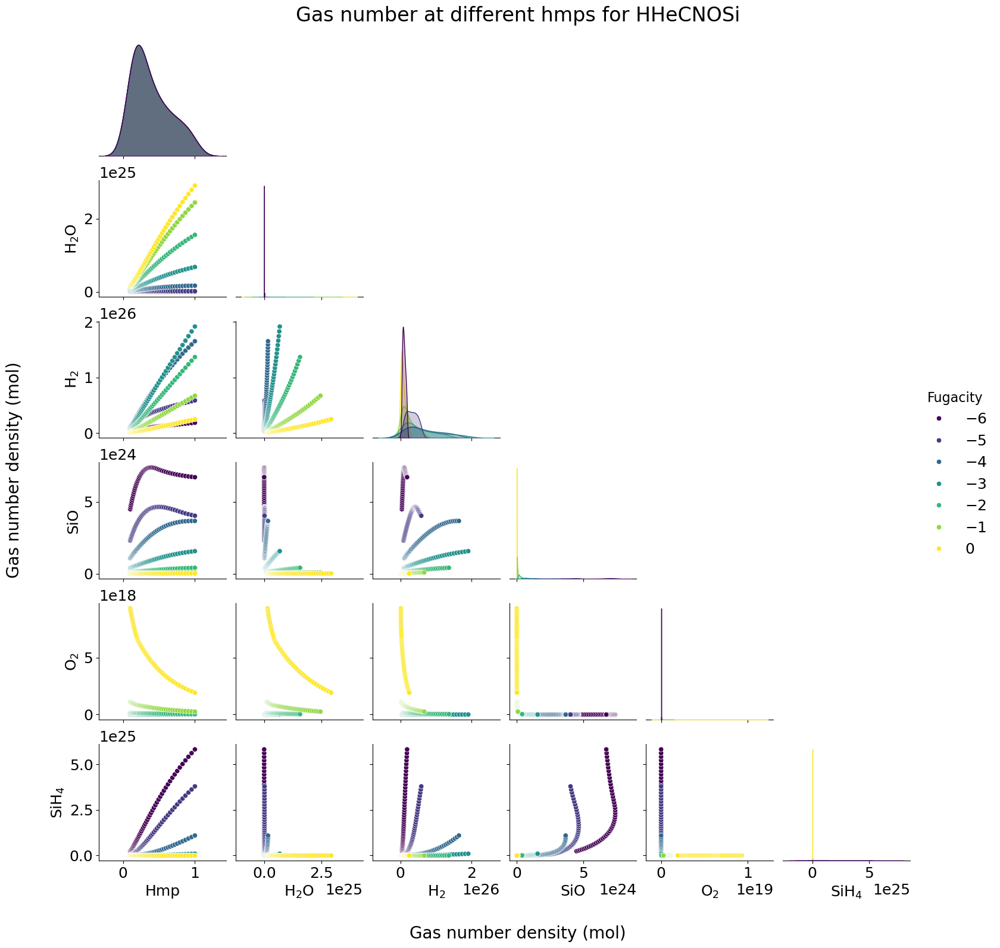

In [34]:
g = sns.pairplot(
    df_gas_numberHHeCNOSi,
    vars=["Hmp",r"H$_2$O", r"H$_2$", "SiO", r"O$_2$",r"SiH$_4$"],
    hue="Fugacity",
    corner=True,
    palette="viridis"
)

new_labels = ["HMPS", "H2O atmospheric mass", "H2 atmospheric mass", "SiO atmospheric mass", "O2 atmospheric mass", "SiH4 atmospheric mass"]
g.fig.suptitle("Gas number at different hmps for HHeCNOSi", y=1.02, fontsize=24)  # overall title
g.fig.text(0.5, -0.02, r"Gas number density (mol)", ha='center', va='center', fontsize=20)
g.fig.text(-0.02, 0.5, r"Gas number density (mol)", ha='center', va='center', rotation=90, fontsize=20)

Text(-0.02, 0.5, 'Gas number density (mol)')

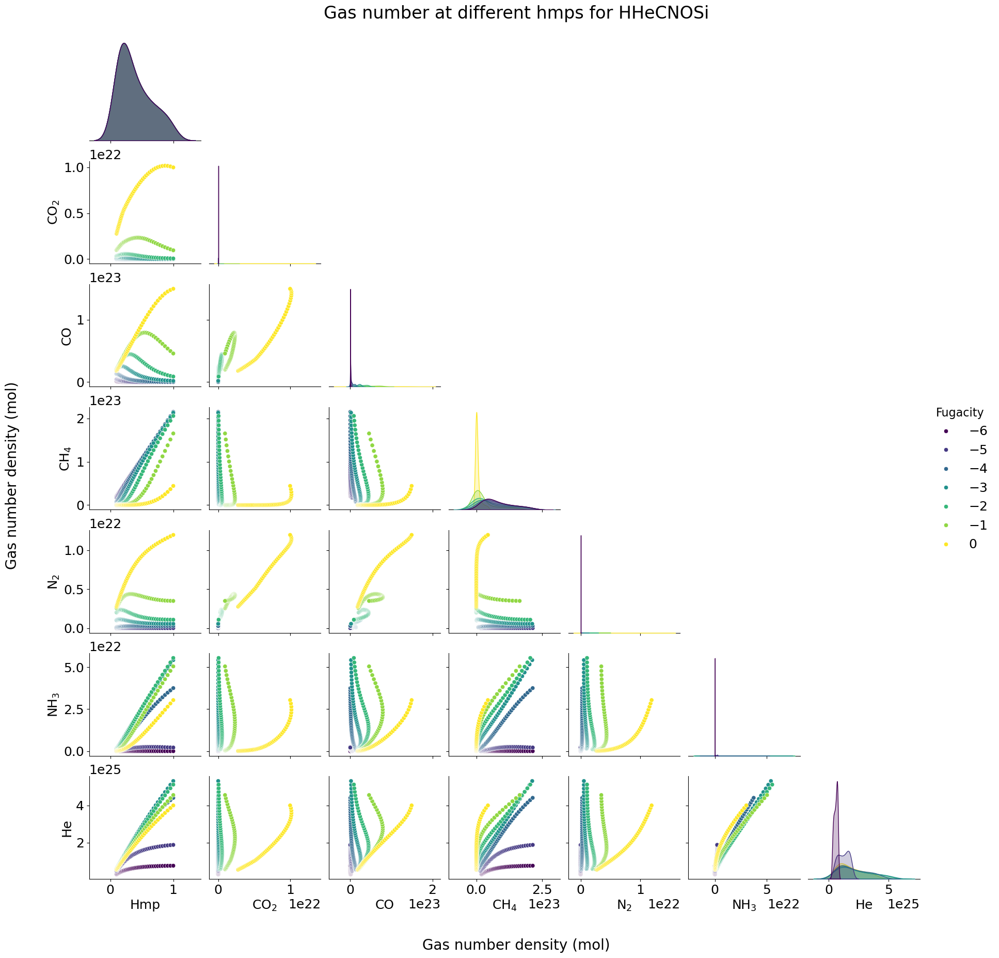

In [36]:
g = sns.pairplot(
    df_gas_numberHHeCNOSi,
    vars=["Hmp",r"CO$_2$","CO",r"CH$_4$",r"N$_2$",r"NH$_3$","He"],
    hue="Fugacity",
    corner=True,
    palette="viridis"
)

new_labels = ["HMPS", "H2O atmospheric mass", "H2 atmospheric mass", "SiO atmospheric mass", "O2 atmospheric mass", "SiH4 atmospheric mass"]
g.fig.suptitle("Gas number at different hmps for HHeCNOSi", y=1.02, fontsize=24)  # overall title
g.fig.text(0.5, -0.02, r"Gas number density (mol)", ha='center', va='center', fontsize=20)
g.fig.text(-0.02, 0.5, r"Gas number density (mol)", ha='center', va='center', rotation=90, fontsize=20)

Text(0.5, 1.02, 'Gas mass at different hmps for HHeCNOSi')

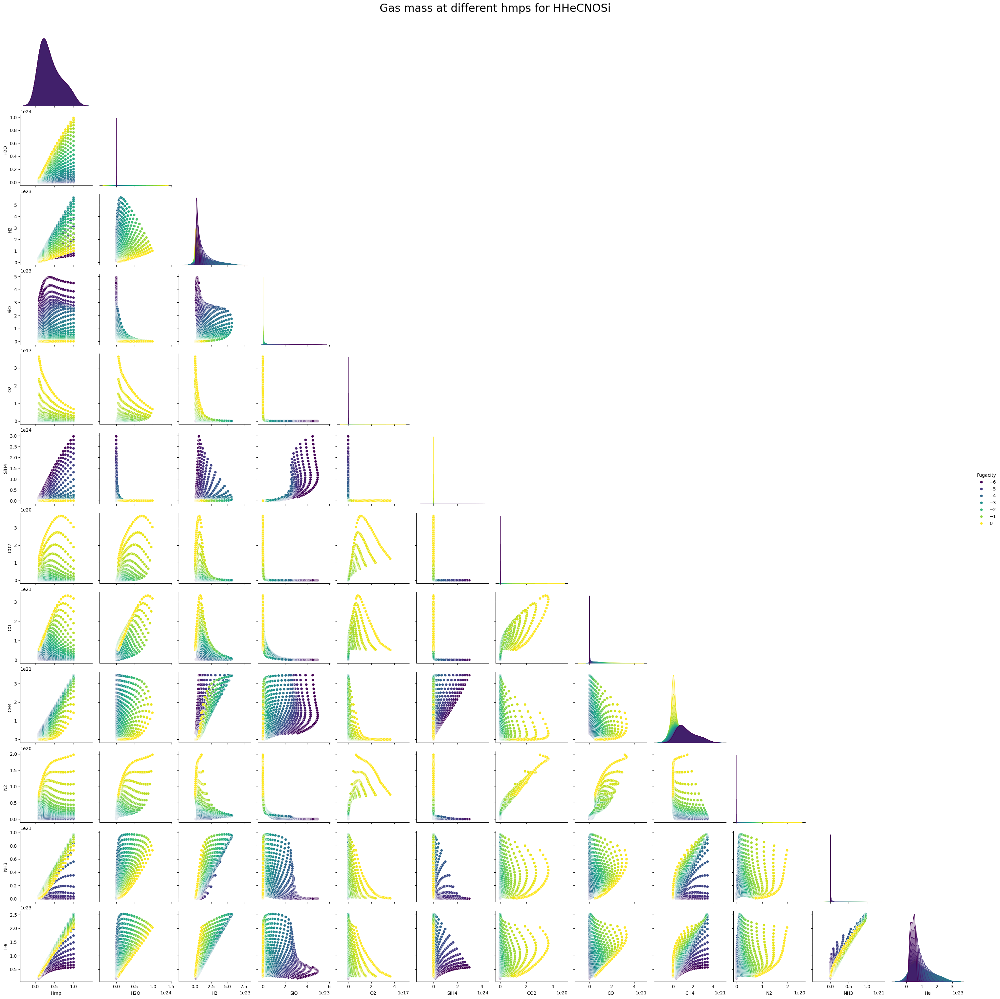

In [52]:
g = sns.pairplot(
    df_gas_massHHeCNOSi,
    vars=["Hmp","H2O", "H2", "SiO", "O2","SiH4","CO2","CO","CH4","N2","NH3","He"],
    hue="Fugacity",
    corner=True,
    palette="viridis"
)

new_labels = ["HMPS", "H2O atmospheric mass", "H2 atmospheric mass", "SiO atmospheric mass", "O2 atmospheric mass", "SiH4 atmospheric mass"]
g.fig.suptitle("Gas mass at different hmps for HHeCNOSi", y=1.02, fontsize=24)  # overall title

Text(0.5, 1.02, 'Gas number density at different hmps for HHeCNOSi')

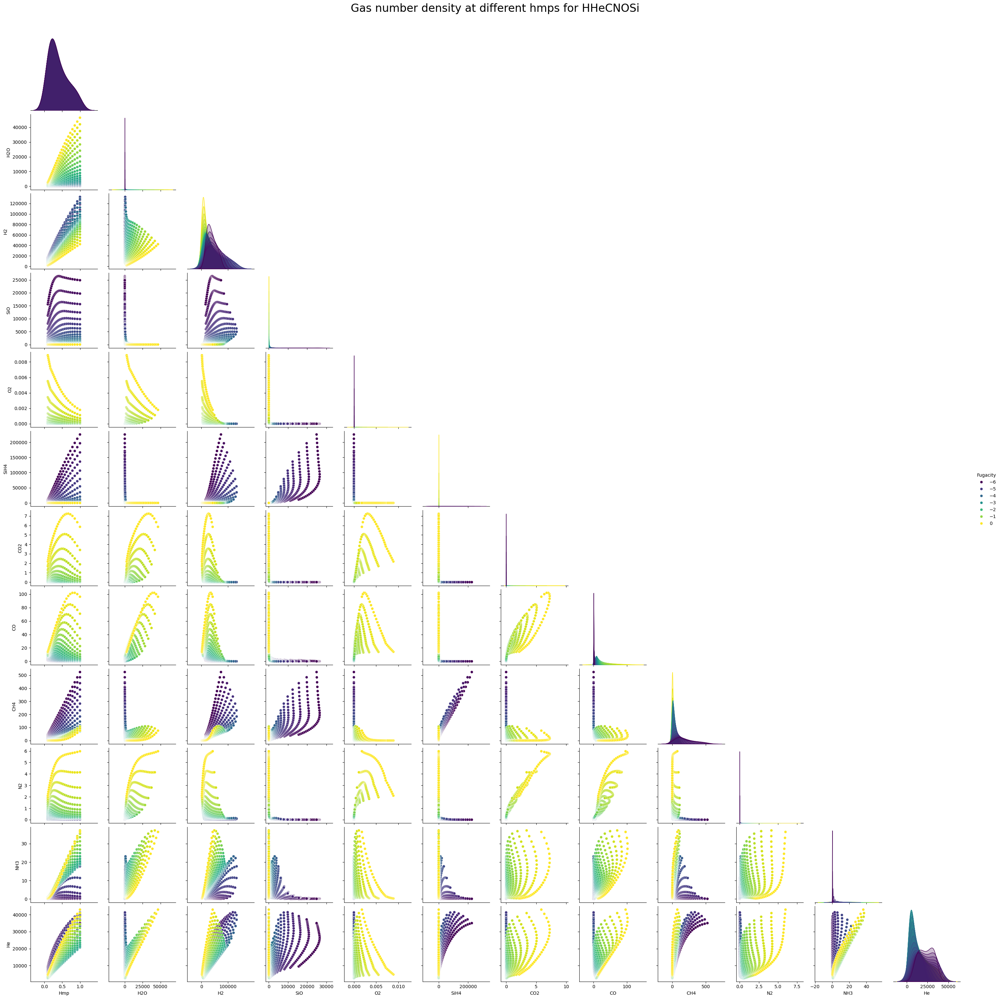

In [53]:
df_total_numberHHeCNOSi = pd.DataFrame(rows_total_number)
g = sns.pairplot(
    df_gas_number_densityHHeCNOSi,
    vars=["Hmp","H2O", "H2", "SiO", "O2","SiH4","CO2","CO","CH4","N2","NH3","He"],
    hue="Fugacity",
    corner=True,
    palette="viridis"
)

new_labels = ["HMPS", "H2O atmospheric mass", "H2 atmospheric mass", "SiO atmospheric mass", "O2 atmospheric mass", "SiH4 atmospheric mass"]
g.fig.suptitle("Gas number density at different hmps for HHeCNOSi", y=1.02, fontsize=24)  # overall title

Text(0.5, 1.02, 'Dissolved number at different hmps for HHeCNOSi')

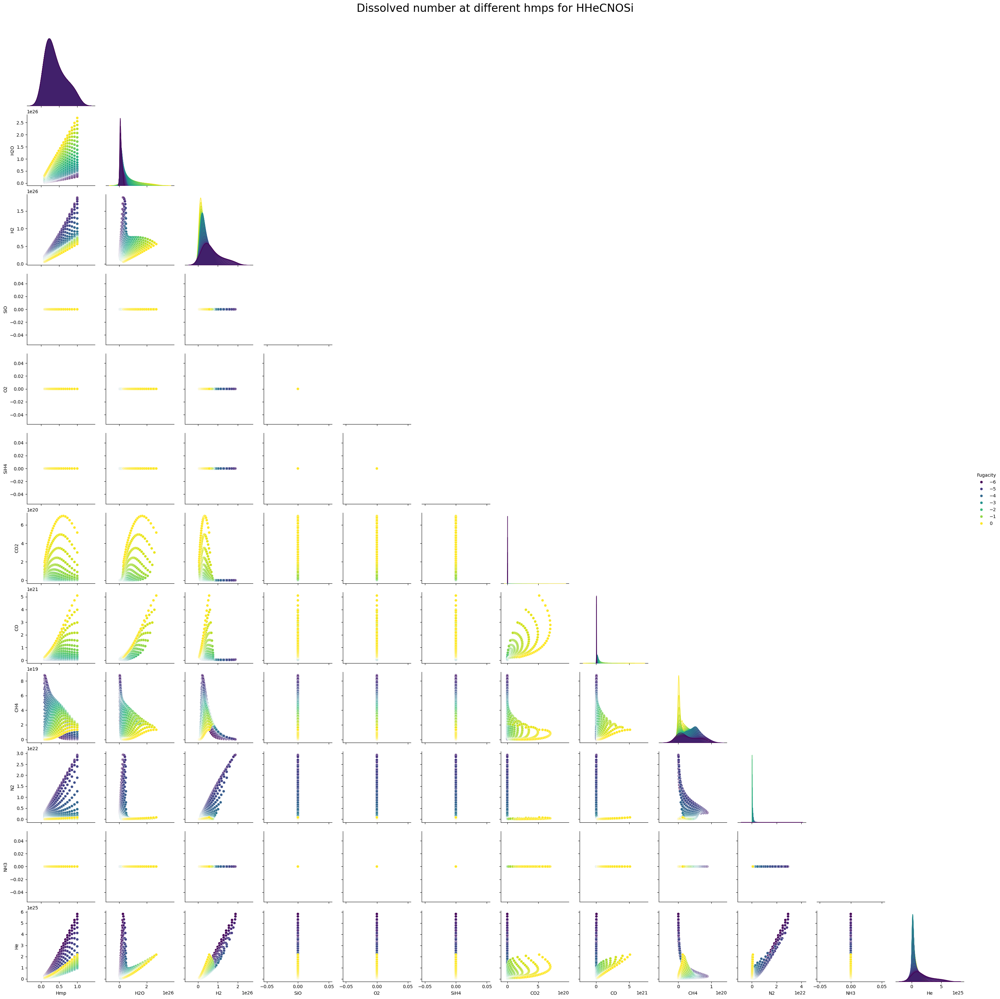

In [54]:
g = sns.pairplot(
    df_dissolved_numberHHeCNOSi,
    vars=["Hmp","H2O", "H2", "SiO", "O2","SiH4","CO2","CO","CH4","N2","NH3","He"],
    hue="Fugacity",
    corner=True,
    palette="viridis"
)

new_labels = ["HMPS", "H2O atmospheric mass", "H2 atmospheric mass", "SiO atmospheric mass", "O2 atmospheric mass", "SiH4 atmospheric mass"]
g.fig.suptitle("Dissolved number at different hmps for HHeCNOSi", y=1.02, fontsize=24)  # overall title

Text(0.5, 1.02, 'Dissolved mass at different hmps for HHeCNOSi')

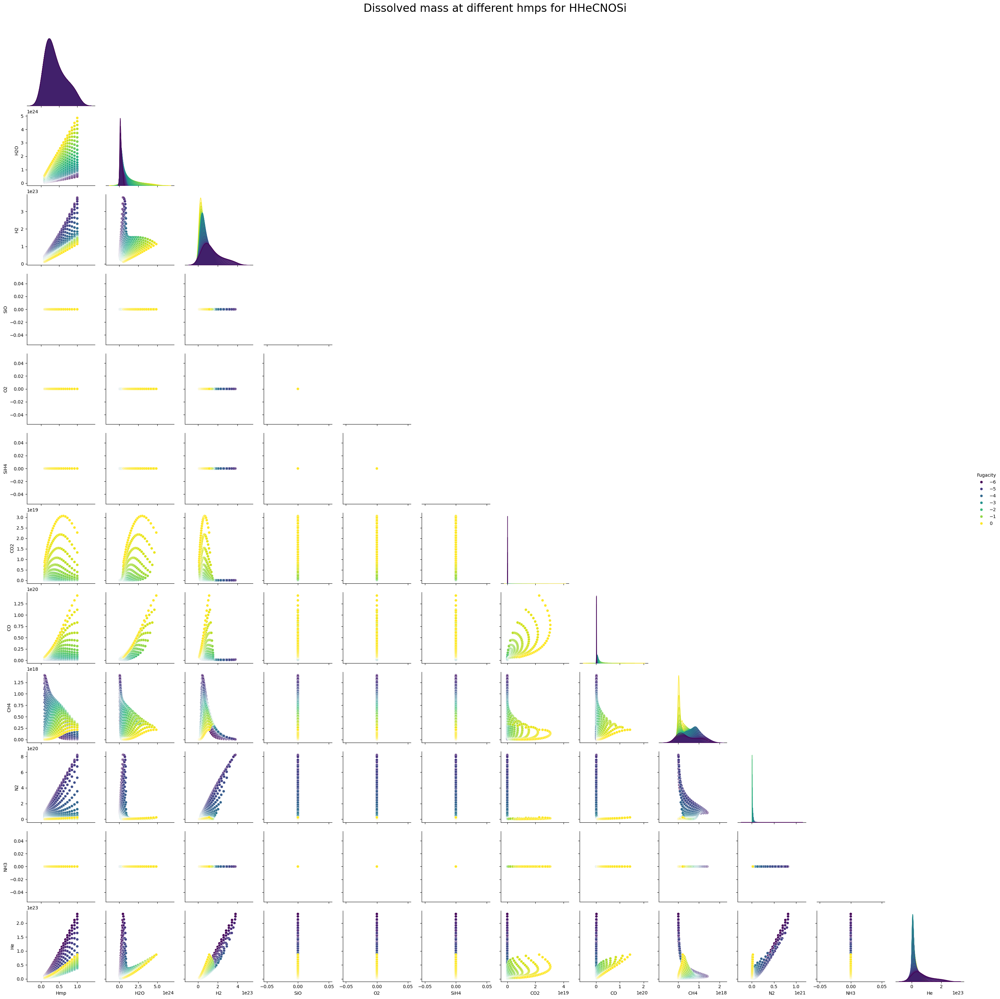

In [55]:
g = sns.pairplot(
    df_dissolved_massHHeCNOSi,
    vars=["Hmp","H2O", "H2", "SiO", "O2","SiH4","CO2","CO","CH4","N2","NH3","He"],
    hue="Fugacity",
    corner=True,
    palette="viridis"
)

new_labels = ["HMPS", "H2O atmospheric mass", "H2 atmospheric mass", "SiO atmospheric mass", "O2 atmospheric mass", "SiH4 atmospheric mass"]
g.fig.suptitle("Dissolved mass at different hmps for HHeCNOSi", y=1.02, fontsize=24)  # overall title

Text(0.5, 1.02, 'Total mass at different hmps for HHeCNOSi')

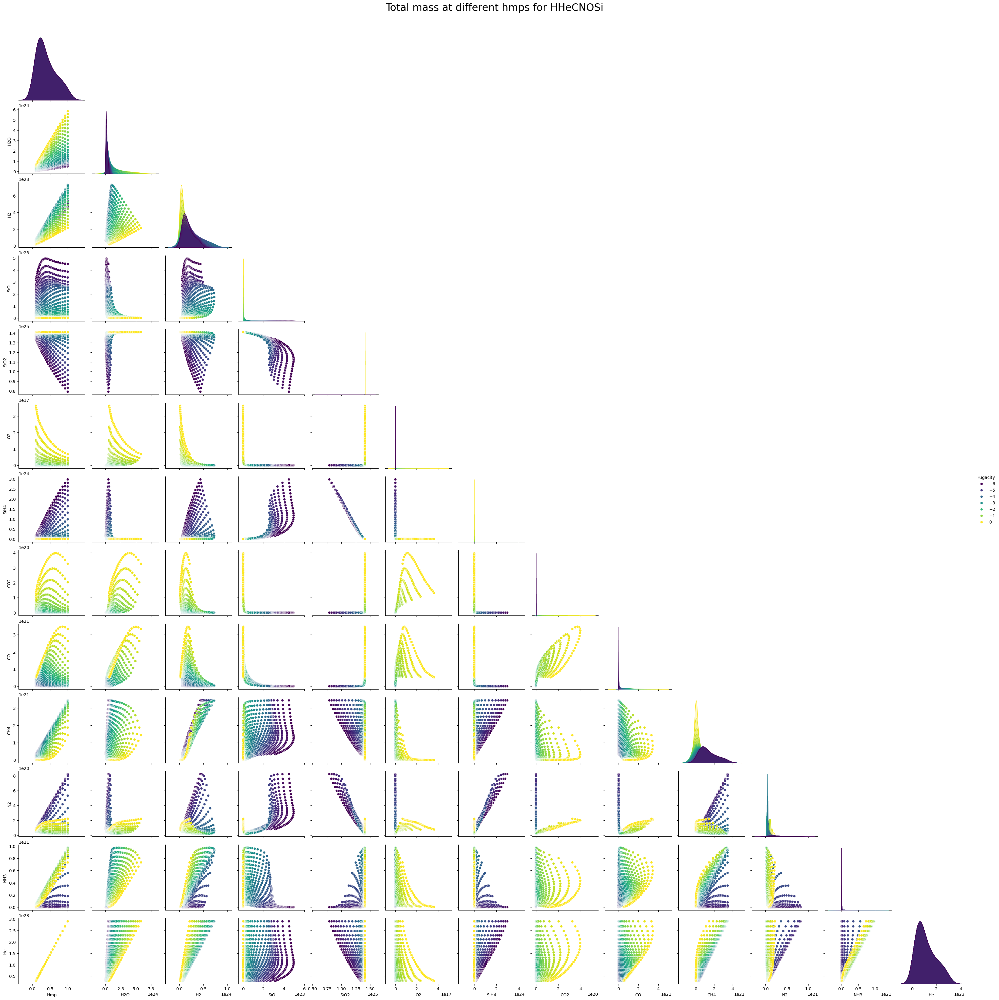

In [56]:
g = sns.pairplot(
    df_total_massHHeCNOSi,
    vars=["Hmp","H2O", "H2", "SiO","SiO2", "O2","SiH4","CO2","CO","CH4","N2","NH3","He"],
    hue="Fugacity",
    corner=True,
    palette="viridis"
)
#partial pressures, units use same scale
new_labels = ["HMPS", "H2O atmospheric mass", "H2 atmospheric mass", "SiO atmospheric mass", "O2 atmospheric mass", "SiH4 atmospheric mass"]
g.fig.suptitle("Total mass at different hmps for HHeCNOSi", y=1.02, fontsize=24)  # overall title

Text(0.5, 1.02, 'Total number at different hmps for HHeCNOSi')

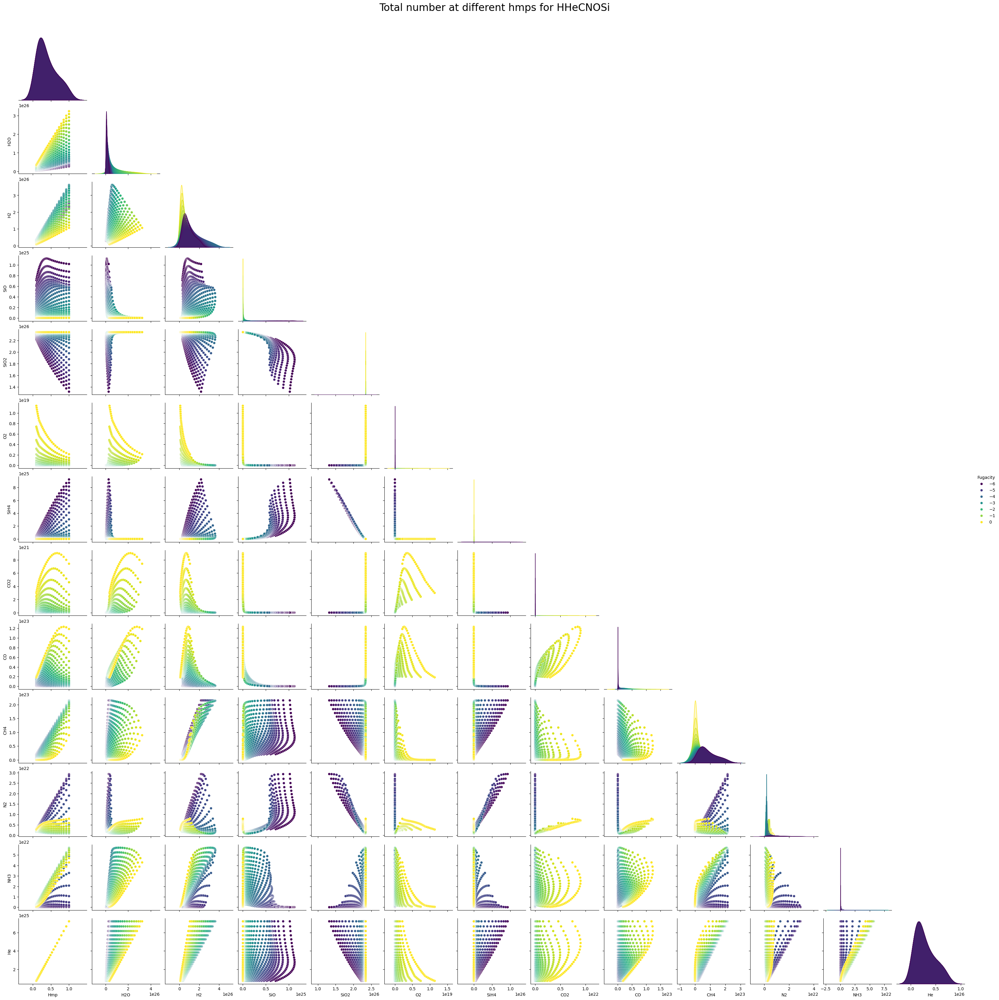

In [58]:
g = sns.pairplot(
    df_total_numberHHeCNOSi,
    vars=["Hmp","H2O", "H2", "SiO","SiO2", "O2","SiH4","CO2","CO","CH4","N2","NH3","He"],
    hue="Fugacity",
    corner=True,
    palette="viridis"
)

new_labels = ["HMPS", "H2O atmospheric mass", "H2 atmospheric mass", "SiO atmospheric mass", "O2 atmospheric mass", "SiH4 atmospheric mass"]
g.fig.suptitle("Total number at different hmps for HHeCNOSi", y=1.02, fontsize=24)  # overall title

# Pressure - Temperature profile

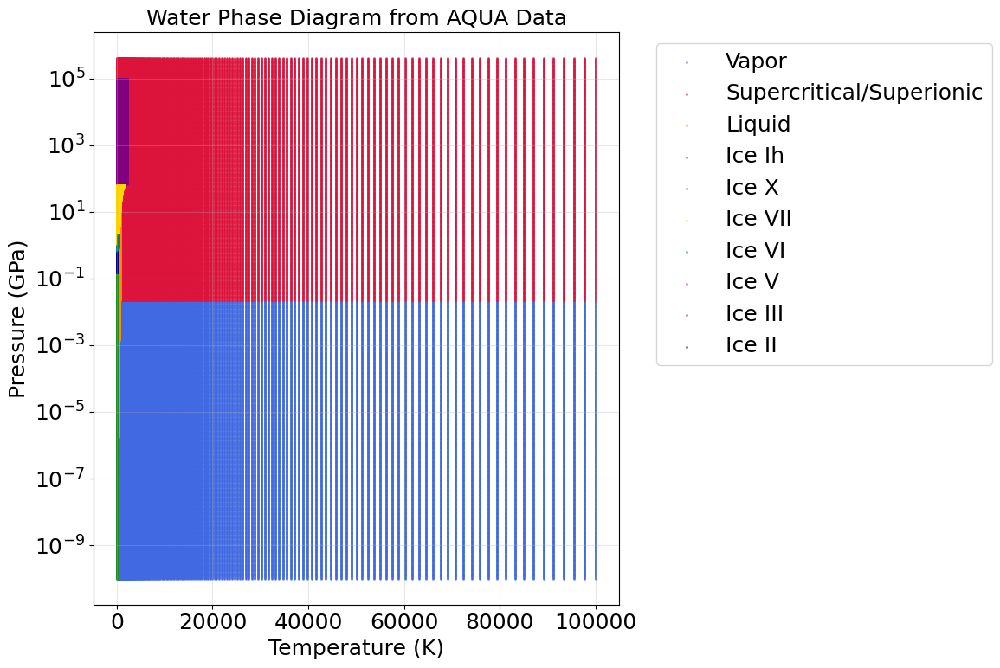

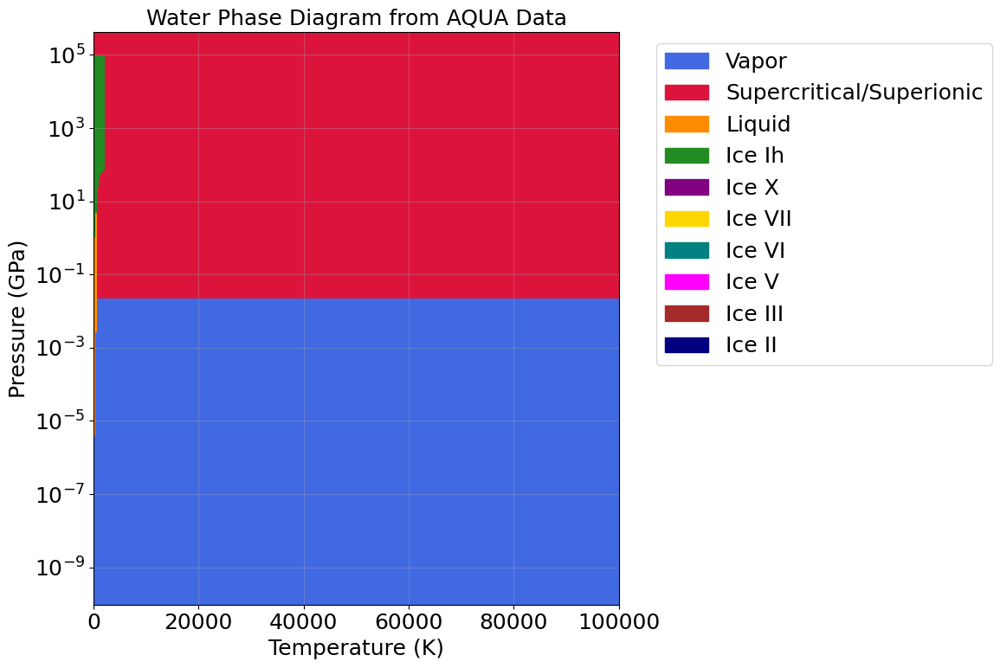

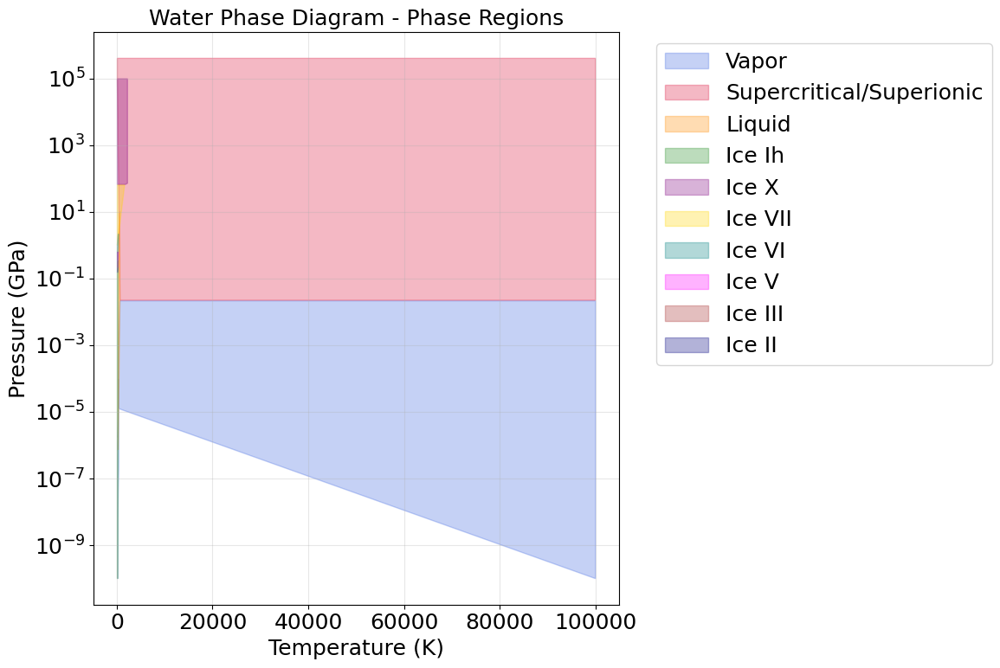

NameError: name 'ListedColormap' is not defined

<Figure size 1200x800 with 0 Axes>

In [68]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import griddata
import matplotlib.patches as mpatches

# Assuming you have your AQUA dataframe loaded
# df = pd.read_csv(...) with columns: temp_K, press_GPa, phase_id

# Your unique phases
unique_phases = ['Vapor', 'Supercritical/Superionic', 'Liquid', 'Ice Ih','Ice X','Ice VII','Ice VI','Ice V','Ice III','Ice II']

# Map phase names to IDs (adjust IDs based on your actual data)
phase_name_to_id = {
    'Vapor': 3,
    'Supercritical/Superionic': 5,
    'Liquid': 4,
    'Ice Ih': -1,
    'Ice X':-10,
    'Ice VII': -7,
    'Ice VI': -6,
    'Ice V':-5,
    'Ice III': -3,
    'Ice II':-2
}
# Create a mapping for plotting colors
phase_colors = {
    'Vapor': 'royalblue',
    'Supercritical/Superionic': 'crimson',
    'Liquid': 'darkorange',
    'Ice Ih': 'forestgreen',
    'Ice X':'purple',
    'Ice VII':'gold',
    'Ice VI': 'teal',
    'Ice V':'magenta',
    'Ice III': 'brown',
    'Ice II':'navy'
}

# Method 1: Scatter plot of all data points (simple)
def plot_phase_scatter(df):
    """Simple scatter plot colored by phase"""
    plt.figure(figsize=(12, 8))
    
    # Plot each phase separately for legend control
    for phase_name in unique_phases:
        phase_id = phase_name_to_id[phase_name]
        mask = df['phase_id'] == phase_id
        plt.scatter(
            df.loc[mask, 'temp_K'],
            df.loc[mask, 'press_GPa'],
            c=phase_colors[phase_name],
            label=phase_name,
            s=1,  # Small points
            alpha=0.6
        )
    
    plt.yscale('log')
    plt.xlabel('Temperature (K)')
    plt.ylabel('Pressure (GPa)')
    plt.title('Water Phase Diagram from AQUA Data')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# Method 2: Create a 2D histogram/pcolormesh (cleaner)
def plot_phase_grid(df, resolution=500):
    """Create a gridded phase diagram"""
    
    # Create a grid
    T_min, T_max = df['temp_K'].min(), df['temp_K'].max()
    P_min, P_max = df['press_GPa'].min(), df['press_GPa'].max()
    
    # Create grid points
    T_grid = np.linspace(T_min, T_max, resolution)
    P_grid = np.logspace(np.log10(P_min), np.log10(P_max), resolution)
    T_mesh, P_mesh = np.meshgrid(T_grid, P_grid)
    
    # Interpolate phase IDs onto grid
    points = df[['temp_K', 'press_GPa']].values
    values = df['phase_id'].values
    
    # Use nearest neighbor interpolation for discrete phases
    phase_grid = griddata(points, values, (T_mesh, P_mesh), method='nearest')
    
    # Create custom colormap
    from matplotlib.colors import ListedColormap, BoundaryNorm
    
    # Define colors for each phase (in order of phase IDs)
    phase_ids_ordered = [-1, 3, 4, 5]  # Ice Ih, Vapor, Liquid, Supercritical
    colors = [phase_colors['Ice Ih'], 
              phase_colors['Vapor'], 
              phase_colors['Liquid'], 
              phase_colors['Supercritical/Superionic']]
    
    cmap = ListedColormap(colors)
    norm = BoundaryNorm([-1.5, 2.5, 3.5, 4.5, 5.5], cmap.N)  # Adjust boundaries
    
    plt.figure(figsize=(12, 8))
    
    # Plot the grid
    im = plt.pcolormesh(T_grid, P_grid, phase_grid, 
                        cmap=cmap, norm=norm, shading='auto')
    
    # Add phase boundaries (optional - you can draw approximate lines)
    # This is where you'd add known phase boundary lines from literature
    
    plt.yscale('log')
    plt.xlabel('Temperature (K)')
    plt.ylabel('Pressure (GPa)')
    plt.title('Water Phase Diagram from AQUA Data')
    
    # Create custom legend
    patches = [mpatches.Patch(color=color, label=name) 
               for name, color in phase_colors.items()]
    plt.legend(handles=patches, bbox_to_anchor=(1.05, 1), loc='upper left')
    
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# Method 3: Contour plot of phase regions
def plot_phase_contours(df):
    """Create contour regions for each phase"""
    
    from scipy.spatial import ConvexHull
    import matplotlib.patches as mpatches
    
    plt.figure(figsize=(12, 8))
    
    # For each phase, create a convex hull of its points
    for phase_name in unique_phases:
        phase_id = phase_name_to_id[phase_name]
        mask = df['phase_id'] == phase_id
        
        if mask.sum() > 3:  # Need at least 3 points for a hull
            points = df.loc[mask, ['temp_K', 'press_GPa']].values
            
            # For log-scale pressure, use log of pressure for hull calculation
            points_log = np.column_stack([points[:, 0], np.log10(points[:, 1])])
            
            try:
                hull = ConvexHull(points_log)
                hull_points = points[hull.vertices]
                
                # Sort by angle for proper polygon
                center = np.mean(hull_points, axis=0)
                angles = np.arctan2(hull_points[:,1] - center[1], 
                                   hull_points[:,0] - center[0])
                hull_points = hull_points[np.argsort(angles)]
                
                # Fill the hull
                plt.fill(hull_points[:, 0], hull_points[:, 1],
                        alpha=0.3, color=phase_colors[phase_name],
                        label=phase_name)
            except:
                # If hull fails, just scatter plot
                plt.scatter(points[:, 0], points[:, 1],
                          c=phase_colors[phase_name],
                          s=1, alpha=0.3, label=phase_name)
    
    plt.yscale('log')
    plt.xlabel('Temperature (K)')
    plt.ylabel('Pressure (GPa)')
    plt.title('Water Phase Diagram - Phase Regions')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# Method 4: Simple heatmap with phase labels
def plot_phase_heatmap(df):
    """Create a 2D histogram showing phase density"""
    
    # Create bins
    T_bins = np.linspace(df['temp_K'].min(), df['temp_K'].max(), 100)
    P_bins = np.logspace(np.log10(df['press_GPa'].min()), 
                         np.log10(df['press_GPa'].max()), 100)
    
    # Create a 2D histogram of phases (majority vote per bin)
    phase_grid = np.zeros((len(P_bins)-1, len(T_bins)-1))
    
    for i in range(len(P_bins)-1):
        for j in range(len(T_bins)-1):
            mask = ((df['temp_K'] >= T_bins[j]) & (df['temp_K'] < T_bins[j+1]) &
                   (df['press_GPa'] >= P_bins[i]) & (df['press_GPa'] < P_bins[i+1]))
            
            if mask.sum() > 0:
                # Get most common phase in this bin
                phase_grid[i, j] = df.loc[mask, 'phase_id'].mode()[0]
            else:
                phase_grid[i, j] = np.nan
    
    plt.figure(figsize=(12, 8))
    
    # Create custom colormap
    colors = [phase_colors['Ice Ih'], 
              phase_colors['Vapor'], 
              phase_colors['Liquid'], 
              phase_colors['Supercritical/Superionic']]
    cmap = ListedColormap(colors)
    
    im = plt.imshow(phase_grid, 
                   extent=[T_bins[0], T_bins[-1], P_bins[0], P_bins[-1]],
                   aspect='auto', origin='lower', cmap=cmap,
                   interpolation='nearest')
    
    plt.yscale('log')
    plt.xlabel('Temperature (K)')
    plt.ylabel('Pressure (GPa)')
    plt.title('Water Phase Diagram - Phase Regions')
    
    # Add legend
    patches = [mpatches.Patch(color=color, label=name) 
               for name, color in phase_colors.items()]
    plt.legend(handles=patches, bbox_to_anchor=(1.05, 1), loc='upper left')
    
    plt.tight_layout()
    plt.show()

# ===== USAGE =====

# Assuming you have your dataframe loaded
#df = pd.read_csv('your_aqua_data.csv', ...)

# Choose one of the plotting methods
plot_phase_scatter(df)      # Simple - shows all data points
plot_phase_grid(df)        # Clean - creates a uniform grid
plot_phase_contours(df)    # Shows approximate regions
plot_phase_heatmap(df)     # Statistical approach

In [62]:
for phase_name in unique_phases:
    phase_id = phase_name_to_id[phase_name]
    mask = df['phase_id'] == phase_id
        
    if mask.sum() > 3:  # Need at least 3 points for a hull
        points = df.loc[mask, ['temp_K', 'press_GPa']].values
            
        # For log-scale pressure, use log of pressure for hull calculation
        points_log = np.column_stack([points[:, 0], np.log10(points[:, 1])])
            
        try:
            hull = ConvexHull(points_log)
            hull_points = points[hull.vertices]
                
            # Sort by angle for proper polygon
            center = np.mean(hull_points, axis=0)
            angles = np.arctan2(hull_points[:,1] - center[1], 
                                hull_points[:,0] - center[0])
            hull_points = hull_points[np.argsort(angles)]
                
            # Fill the hull
            plt.fill(hull_points[:, 0], hull_points[:, 1],
                    alpha=0.3, color=phase_colors[phase_name],
                    label=phase_name)
        except:
            # If hull fails, just scatter plot
            plt.scatter(points[:, 0], points[:, 1],
                        c=phase_colors[phase_name],
                        s=1, alpha=0.3, label=phase_name)
    
plt.yscale('log')
plt.xlabel('Temperature (K)')
plt.xlim(500, 3500)
plt.ylim(1e-4, 1e2)
plt.ylabel('Pressure (GPa)')
plt.title('Water Phase Diagram - Phase Regions')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

NameError: name 'df' is not defined

[848.8319427567544, 857.3585169602994, 866.0228043278989, 874.825468285063, 883.7671872674109, 892.8486559616949, 902.070586476539, 911.4337094442651, 920.9387750554381, 930.5865540280402, 940.3778385133792, 950.3134429410104, 960.3942048050941, 970.6209853947147, 980.9946704707676, 991.516170892071, 1002.1864231933926, 1013.0063901180804, 1023.9770611079861, 1035.0994527533344, 1046.374609205154, 1057.8036025528315, 1069.3875331692855, 1081.1275300261868, 1093.0247509815717, 1105.0803830421064, 1117.2956426021824, 1129.6717756619178, 1142.2100580260585, 1154.9117954856672, 1167.7783239844055, 1180.8110097711099, 1194.0112495402748, 1207.380470561966, 1220.9201308025913, 1234.6317190378784, 1248.5167549593166, 1262.5767892752453, 1276.813403807687, 1291.228211585954, 1305.8228569379837, 1320.5990155802876, 1335.5583947073385, 1350.702733081152, 1366.0338011217716, 1381.553400999297, 1397.2633667280563, 1413.165564263469, 1429.2618916020967, 1445.5542788853486, 1462.044688507249, 1478.7

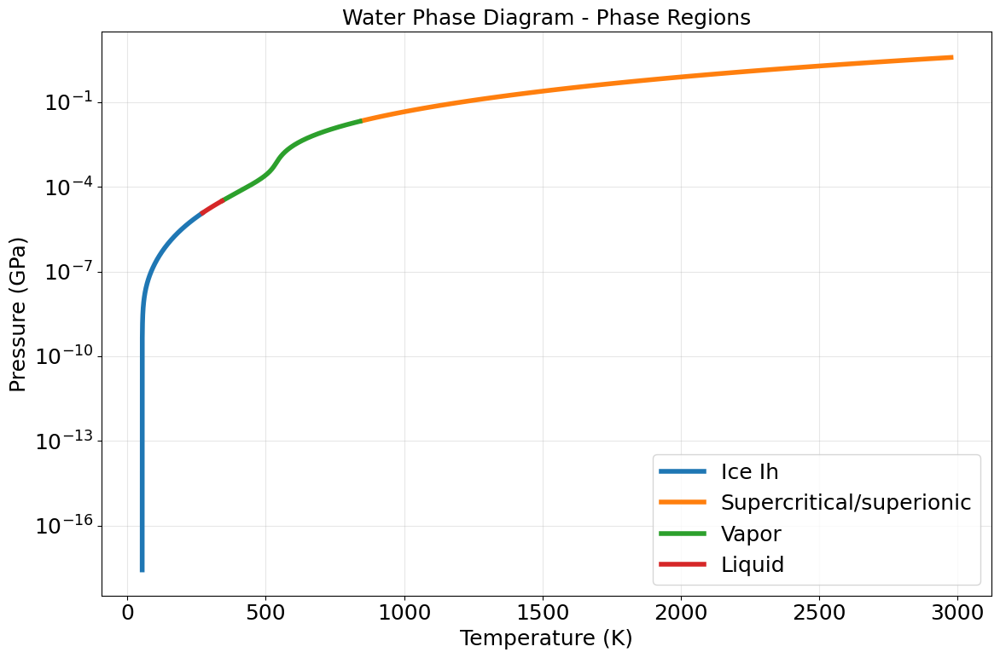

In [58]:
from scipy.spatial import ConvexHull
import matplotlib.patches as mpatches
    
plt.figure(figsize=(12, 8))
ice_indices = []
supercritical_indices = []
vapor_indices = []
liquid_indices = []
hmp = hmps[49]
filename = f"./excel_Uranus_solar_3000K/HOSi/rho{rho_centre}/core_boundary/HOSi_magma_sol_real_{init_metallicity}xsolar_melt{round(mantle_melt_fraction * 100)}_fO2{shift}_2.xlsx"
Pressure = pd.read_excel(filename, sheet_name="state")["pressure"]
Pressures, Temperatures = Pressure_Temperatures(3000, tau, Pressure[49], 1e7)
Pressures = Pressures*10**(-4)
for i in range(len(Temperatures)):
    result = get_phase(Temperatures[i], Pressures[i])
    if result == "Ice Ih":
        ice_indices.append(i)
    elif result == "Supercritical":
        supercritical_indices.append(i)
    elif result == "Vapor":
        vapor_indices.append(i)
    elif result == "Liquid":
        liquid_indices.append(i)

ice_temperatures = [Temperatures[i] for i in ice_indices]
ice_pressures = [Pressures[i] for i in ice_indices]
supercritical_temperatures = [Temperatures[i] for i in supercritical_indices]
supercritical_pressures = [Pressures[i] for i in supercritical_indices]
print(supercritical_temperatures)
vapor_temperatures = [Temperatures[i] for i in vapor_indices]
vapor_pressures = [Pressures[i] for i in vapor_indices]
liquid_temperatures = [Temperatures[i] for i in liquid_indices]
liquid_pressures = [Pressures[i] for i in liquid_indices]
# For each phase, create a convex hull of its points
plt.plot(ice_temperatures, ice_pressures, lw=4, ls="-",label=f"Ice Ih")
plt.plot(supercritical_temperatures, supercritical_pressures, lw=4, ls="-",label=f"Supercritical/superionic")   
plt.plot(vapor_temperatures, vapor_pressures, lw=4, ls="-",label=f"Vapor")   
plt.plot(liquid_temperatures, liquid_pressures, lw=4, ls="-",label=f"Liquid")   
    
plt.yscale('log')
plt.xlabel('Temperature (K)')
#plt.xlim(500, 3500)
#plt.ylim(1e-4, 1e2)
plt.ylabel('Pressure (GPa)')
plt.title('Water Phase Diagram - Phase Regions')
#plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# HOSi atmosphere modelling

0      True
1      True
2      True
3      True
4      True
5      True
6      True
7     False
8     False
9     False
10    False
11    False
12    False
13    False
14    False
15    False
16    False
17    False
18    False
19    False
dtype: bool
0      True
1      True
2      True
3      True
4      True
5      True
6     False
7     False
8     False
9     False
10    False
11    False
12    False
13    False
14    False
15    False
16    False
17    False
18    False
19    False
dtype: bool
0      True
1      True
2      True
3      True
4      True
5     False
6     False
7     False
8     False
9     False
10    False
11    False
12    False
13    False
14    False
15    False
16    False
17    False
18    False
19    False
dtype: bool
0     False
1     False
2     False
3     False
4     False
5     False
6     False
7     False
8     False
9     False
10    False
11    False
12    False
13    False
14    False
15    False
16    False
17    False
18    False
19    False
dtyp

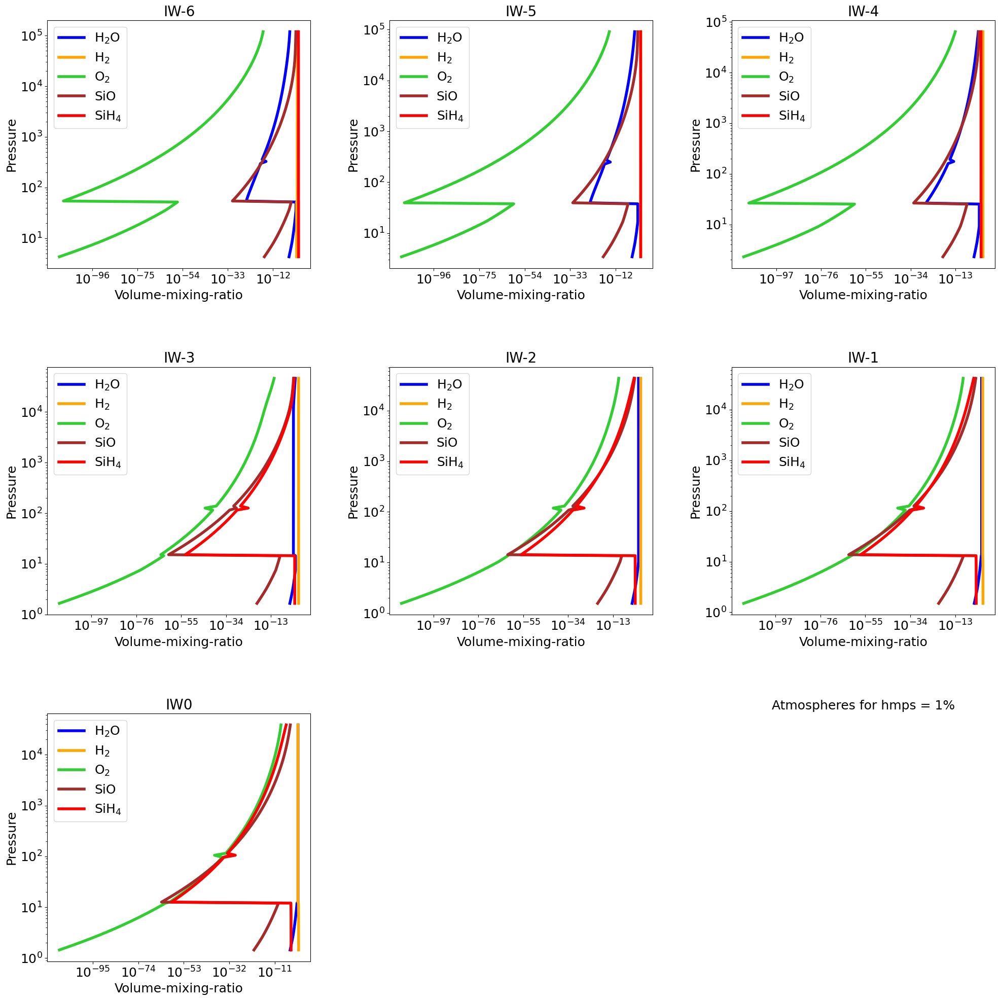

In [12]:
fig, axes = plt.subplots(
    nrows=3,   # 5 rows
    ncols=3,   # 6 columns
    figsize=(20, 20)  # width x height in inches, adjust as needed
)
init_metallicity = 1
mantle_melt_fraction = 1
rho_centre = 3000 
hmp = hmps[49]
hmp_text = f"{hmp:.2g}"
axes = axes.flatten()  # length = 5*6 = 30
# Create 7 plots
for i in range(7):
    shift = f"{fO2_log10_shifts[i]:.2g}"
    axes[i].set_title(f"IW{shift}", fontsize=20)
    filename_inter = f"./excel_Uranus_solar_3000K/HOSi/rho{rho_centre}/atmosphere/HOSi_atmo_sol_real_{init_metallicity}xsolar_melt{round(mantle_melt_fraction * 100)}_fO2{shift}_{hmp_text}Hwt_interH20.xlsx"
    filename_gas = f"./excel_Uranus_solar_3000K/HOSi/rho{rho_centre}/atmosphere/HOSi_atmo_sol_real_{init_metallicity}xsolar_melt{round(mantle_melt_fraction * 100)}_fO2{shift}_{hmp_text}Hwt_gasH20.xlsx"
    filename_condensed = f"./excel_Uranus_solar_3000K/HOSi/rho{rho_centre}/atmosphere/HOSi_atmo_sol_real_{init_metallicity}xsolar_melt{round(mantle_melt_fraction * 100)}_fO2{shift}_{hmp_text}Hwt_condensedH20.xlsx"

    solver_row_gas = pd.read_excel(filename_gas, sheet_name="solver")
    mask_gas = solver_row_gas["converged"]
    Temperatures_gas = pd.read_excel(filename_gas, sheet_name="state")["temperature"][mask_gas]
    Lower_temperature = Temperatures_gas.iloc[0]
    
    solver_row_inter = pd.read_excel(filename_inter, sheet_name="solver")
    state_row_inter = pd.read_excel(filename_inter, sheet_name="state")
    
    solver_row_condensed = pd.read_excel(filename_condensed, sheet_name="solver")
    
    mask_inter= solver_row_inter["converged"] & (state_row_inter["temperature"] < Lower_temperature)
    print(mask_inter)
    
    mask_condensed = solver_row_condensed["converged"]
    # Pressures
    H2O_pressure =[]
    H2_pressure = []
    O2_pressure = []
    SiO_pressure = []
    SiH4_pressure = [] 
    tot_pressure = []

    H2O_volume_mixing_ratio =[]
    H2_volume_mixing_ratio = []
    O2_volume_mixing_ratio = []
    SiO_volume_mixing_ratio = []
    SiH4_volume_mixing_ratio = [] 

    H2O_pressure.append(pd.read_excel(filename_condensed, sheet_name="H2O_g")["pressure"][mask_condensed])
    H2O_pressure.append(pd.read_excel(filename_inter, sheet_name="H2O_g")["pressure"][mask_inter])
    H2O_pressure.append(pd.read_excel(filename_gas, sheet_name="H2O_g")["pressure"][mask_gas])
    H2_pressure.append(pd.read_excel(filename_condensed, sheet_name="H2_g")["pressure"][mask_condensed])
    H2_pressure.append(pd.read_excel(filename_inter, sheet_name="H2_g")["pressure"][mask_inter])
    H2_pressure.append(pd.read_excel(filename_gas, sheet_name="H2_g")["pressure"][mask_gas])
    O2_pressure.append(pd.read_excel(filename_condensed, sheet_name="O2_g")["pressure"][mask_condensed])
    O2_pressure.append(pd.read_excel(filename_inter, sheet_name="O2_g")["pressure"][mask_inter])
    O2_pressure.append(pd.read_excel(filename_gas, sheet_name="O2_g")["pressure"][mask_gas])

    SiO_pressure.append(pd.read_excel(filename_condensed, sheet_name="OSi_g")["pressure"][mask_condensed])
    SiO_pressure.append(pd.read_excel(filename_inter, sheet_name="OSi_g")["pressure"][mask_inter])
    SiO_pressure.append(pd.read_excel(filename_gas, sheet_name="OSi_g")["pressure"][mask_gas])

    SiH4_pressure.append(pd.read_excel(filename_condensed, sheet_name="H4Si_g")["pressure"][mask_condensed])
    SiH4_pressure.append(pd.read_excel(filename_inter, sheet_name="H4Si_g")["pressure"][mask_inter])
    SiH4_pressure.append(pd.read_excel(filename_gas, sheet_name="H4Si_g")["pressure"][mask_gas])

    #He_pressure = pd.read_excel(filename, sheet_name="He_g")["pressure"][mask]
    #CO2_pressure = pd.read_excel(filename, sheet_name="CO2_g")["pressure"][mask]
    #CO_pressure = pd.read_excel(filename, sheet_name="CO_g")["pressure"][mask]
    #CH4_pressure = pd.read_excel(filename, sheet_name="CH4_g")["pressure"][mask]
    #N2_pressure = pd.read_excel(filename, sheet_name="N2_g")["pressure"][mask]
    #NH3_pressure = pd.read_excel(filename, sheet_name="H3N_g")["pressure"][mask]
    tot_pressure.append(pd.read_excel(filename_condensed, sheet_name="state")["pressure"][mask_condensed])
    tot_pressure.append(pd.read_excel(filename_inter, sheet_name="state")["pressure"][mask_inter])
    tot_pressure.append(pd.read_excel(filename_gas, sheet_name="state")["pressure"][mask_gas])


    H2O_pressure = np.concatenate(H2O_pressure)
    H2_pressure = np.concatenate(H2_pressure)
    O2_pressure = np.concatenate(O2_pressure)
    SiO_pressure = np.concatenate(SiO_pressure)
    SiH4_pressure = np.concatenate(SiH4_pressure)
    tot_pressure = np.concatenate(tot_pressure)

    H2O_volume_mixing_ratio.append(pd.read_excel(filename_condensed, sheet_name="H2O_g")["volume_mixing_ratio"][mask_condensed])
    H2O_volume_mixing_ratio.append(pd.read_excel(filename_inter, sheet_name="H2O_g")["volume_mixing_ratio"][mask_inter])
    H2O_volume_mixing_ratio.append(pd.read_excel(filename_gas, sheet_name="H2O_g")["volume_mixing_ratio"][mask_gas])

    H2_volume_mixing_ratio.append(pd.read_excel(filename_condensed, sheet_name="H2_g")["volume_mixing_ratio"][mask_condensed])
    H2_volume_mixing_ratio.append(pd.read_excel(filename_inter, sheet_name="H2_g")["volume_mixing_ratio"][mask_inter])
    H2_volume_mixing_ratio.append(pd.read_excel(filename_gas, sheet_name="H2_g")["volume_mixing_ratio"][mask_gas])

    O2_volume_mixing_ratio.append(pd.read_excel(filename_condensed, sheet_name="O2_g")["volume_mixing_ratio"][mask_condensed])
    O2_volume_mixing_ratio.append(pd.read_excel(filename_inter, sheet_name="O2_g")["volume_mixing_ratio"][mask_inter])
    O2_volume_mixing_ratio.append(pd.read_excel(filename_gas, sheet_name="O2_g")["volume_mixing_ratio"][mask_gas])

    SiO_volume_mixing_ratio.append(pd.read_excel(filename_condensed, sheet_name="OSi_g")["volume_mixing_ratio"][mask_condensed])
    SiO_volume_mixing_ratio.append(pd.read_excel(filename_inter, sheet_name="OSi_g")["volume_mixing_ratio"][mask_inter])
    SiO_volume_mixing_ratio.append(pd.read_excel(filename_gas, sheet_name="OSi_g")["volume_mixing_ratio"][mask_gas])

    SiH4_volume_mixing_ratio.append(pd.read_excel(filename_condensed, sheet_name="H4Si_g")["volume_mixing_ratio"][mask_condensed])
    SiH4_volume_mixing_ratio.append(pd.read_excel(filename_inter, sheet_name="H4Si_g")["volume_mixing_ratio"][mask_inter])
    SiH4_volume_mixing_ratio.append(pd.read_excel(filename_gas, sheet_name="H4Si_g")["volume_mixing_ratio"][mask_gas])
    

    H2O_volume_mixing_ratio = np.concatenate(H2O_volume_mixing_ratio)
    H2_volume_mixing_ratio = np.concatenate(H2_volume_mixing_ratio)
    O2_volume_mixing_ratio = np.concatenate(O2_volume_mixing_ratio)
    SiO_volume_mixing_ratio = np.concatenate(SiO_volume_mixing_ratio)
    SiH4_volume_mixing_ratio = np.concatenate(SiH4_volume_mixing_ratio)

    #He_volume_mixing_ratio = pd.read_excel(filename, sheet_name="He_g")["volume_mixing_ratio"][mask]
    #CO2_volume_mixing_ratio = pd.read_excel(filename, sheet_name="CO2_g")["volume_mixing_ratio"][mask]
    #CO_volume_mixing_ratio = pd.read_excel(filename, sheet_name="CO_g")["volume_mixing_ratio"][mask]
    #CH4_volume_mixing_ratio = pd.read_excel(filename, sheet_name="CH4_g")["volume_mixing_ratio"][mask]
    #N2_volume_mixing_ratio = pd.read_excel(filename, sheet_name="N2_g")["volume_mixing_ratio"][mask]
    #NH3_volume_mixing_ratio = pd.read_excel(filename, sheet_name="H3N_g")["volume_mixing_ratio"][mask]

    #He_volume_mixing_ratio = pd.read_excel(filename, sheet_name="He_g")["volume_mixing_ratio"]
    #CO2_volume_mixing_ratio = pd.read_excel(filename, sheet_name="CO2_g")["volume_mixing_ratio"]
    #CO_volume_mixing_ratio = pd.read_excel(filename, sheet_name="CO_g")["volume_mixing_ratio"]
    #CH4_volume_mixing_ratio = pd.read_excel(filename, sheet_name="CH4_g")["volume_mixing_ratio"]
    #N2_volume_mixing_ratio = pd.read_excel(filename, sheet_name="N2_g")["volume_mixing_ratio"]
    #NH3_volume_mixing_ratio = pd.read_excel(filename, sheet_name="H3N_g")["volume_mixing_ratio"]

    axes[i].plot(H2O_volume_mixing_ratio,tot_pressure, color=color_H2O, lw=4, ls="-", label="H$_2$O")
    axes[i].plot(H2_volume_mixing_ratio,tot_pressure, color=color_H2, lw=4, ls="-", label="H$_2$")
    axes[i].plot(O2_volume_mixing_ratio,tot_pressure, color=color_O2, lw=4, ls="-", label="O$_2$")
    axes[i].plot(SiO_volume_mixing_ratio,tot_pressure, color=color_SiO, lw=4, ls="-", label="SiO")
    axes[i].plot(SiH4_volume_mixing_ratio,tot_pressure, color=color_SiH4, lw=4, ls="-", label="SiH$_4$")
    #ax.plot(He_volume_mixing_ratio,tot_pressure, color=color_He, lw=4, ls="-", label="He")
    #ax.plot(CO2_volume_mixing_ratio,tot_pressure, color=color_CO2, lw=4, ls="-", label="CO$_2$")
    #ax.plot(CO_volume_mixing_ratio,tot_pressure, color=color_CO, lw=4, ls="-", label="CO")
    #ax.plot(CH4_volume_mixing_ratio,tot_pressure,color=color_CH4, lw=4, ls="-", label="CH$_4$")
    #ax.plot(N2_volume_mixing_ratio,tot_pressure, color=color_N2, lw=4, ls="-", label="N$_2$")
    #ax.plot(NH3_volume_mixing_ratio,tot_pressure, color=color_NH3, lw=4, ls="-", label="NH$_3$")

    # Set labels and title
    axes[i].set_xlabel('Volume-mixing-ratio')
    axes[i].set_ylabel('Pressure')
    axes[i].set_xscale('log') 
    axes[i].set_yscale('log') 
    # Add a legend
    axes[i].legend()
for i in range(7, 9):
    axes[i].axis("off")

plt.tight_layout()
plt.title("Atmospheres for hmps = 1%")
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.show()

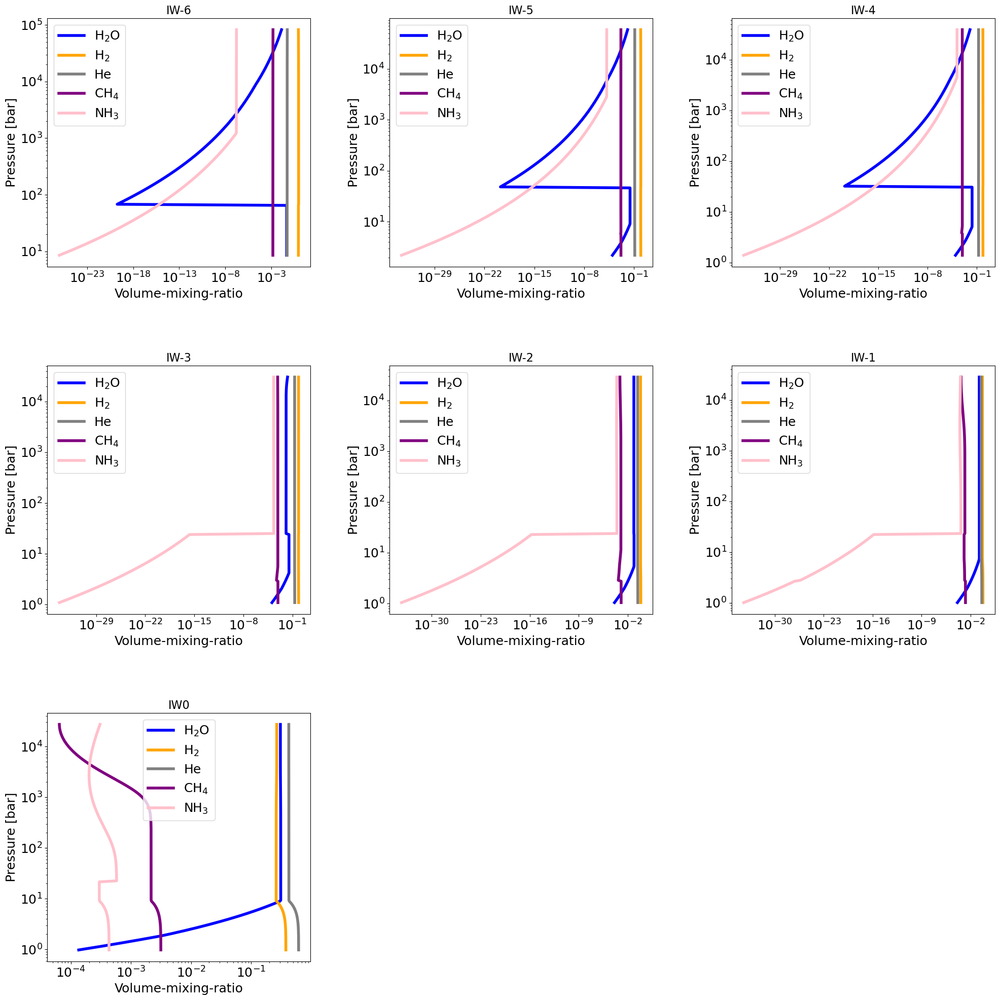

In [13]:
fig, axes = plt.subplots(
    nrows=3,   # 5 rows
    ncols=3,   # 6 columns
    figsize=(20, 20)  # width x height in inches, adjust as needed
)
init_metallicity = 1
mantle_melt_fraction = 1
rho_centre = 3000 
hmp = hmps[49]
hmp_text = f"{hmp:.2g}"
axes = axes.flatten()  # length = 5*6 = 30
# Create 7 plots
for i in range(7):
    shift = f"{fO2_log10_shifts[i]:.2g}"
    axes[i].set_title(f"IW{shift}", fontsize=16)
    filename_inter = f"./excel_Uranus_solar_3000K/HHeCNOSi/rho{rho_centre}/atmosphere/HHeCNOSi_atmo_sol_real_{init_metallicity}xsolar_melt{round(mantle_melt_fraction * 100)}_fO2{shift}_{hmp_text}Hwt_gasH2O.xlsx"
    filename_gas = f"./excel_Uranus_solar_3000K/HHeCNOSi/rho{rho_centre}/atmosphere/HHeCNOSi_atmo_sol_real_{init_metallicity}xsolar_melt{round(mantle_melt_fraction * 100)}_fO2{shift}_{hmp_text}Hwt_gasH2O.xlsx"
    filename_condensed = f"./excel_Uranus_solar_3000K/HHeCNOSi/rho{rho_centre}/atmosphere/HHeCNOSi_atmo_sol_real_{init_metallicity}xsolar_melt{round(mantle_melt_fraction * 100)}_fO2{shift}_{hmp_text}Hwt_condensedH2O.xlsx"

    solver_row_gas = pd.read_excel(filename_gas, sheet_name="solver")
    mask_gas = solver_row_gas["converged"]
    Temperatures_gas = pd.read_excel(filename_gas, sheet_name="state")["temperature"][mask_gas]
    Lower_temperature = Temperatures_gas.iloc[0]
    
    solver_row_inter = pd.read_excel(filename_inter, sheet_name="solver")
    state_row_inter = pd.read_excel(filename_inter, sheet_name="state")
    
    solver_row_condensed = pd.read_excel(filename_condensed, sheet_name="solver")
    
    mask_inter= solver_row_inter["converged"] & (state_row_inter["temperature"] < Lower_temperature)
    mask_condensed = solver_row_condensed["converged"]
    # Pressures
    H2O_pressure =[]
    H2_pressure = []
    O2_pressure = []
    SiO_pressure = []
    SiH4_pressure = [] 
    tot_pressure = []

    H2O_volume_mixing_ratio =[]
    H2_volume_mixing_ratio = []
    O2_volume_mixing_ratio = []
    SiO_volume_mixing_ratio = []
    SiH4_volume_mixing_ratio = [] 
    He_volume_mixing_ratio =[]
    CO2_volume_mixing_ratio = []
    CO_volume_mixing_ratio = []
    CH4_volume_mixing_ratio = []
    N2_volume_mixing_ratio = [] 
    NH3_volume_mixing_ratio = [] 

    H2O_pressure.append(pd.read_excel(filename_condensed, sheet_name="H2O_g")["pressure"][mask_condensed])
    H2O_pressure.append(pd.read_excel(filename_inter, sheet_name="H2O_g")["pressure"][mask_inter])
    H2O_pressure.append(pd.read_excel(filename_gas, sheet_name="H2O_g")["pressure"][mask_gas])

    H2_pressure.append(pd.read_excel(filename_condensed, sheet_name="H2_g")["pressure"][mask_condensed])
    H2_pressure.append(pd.read_excel(filename_inter, sheet_name="H2_g")["pressure"][mask_inter])
    H2_pressure.append(pd.read_excel(filename_gas, sheet_name="H2_g")["pressure"][mask_gas])

    O2_pressure.append(pd.read_excel(filename_condensed, sheet_name="O2_g")["pressure"][mask_condensed])
    O2_pressure.append(pd.read_excel(filename_inter, sheet_name="O2_g")["pressure"][mask_inter])
    O2_pressure.append(pd.read_excel(filename_gas, sheet_name="O2_g")["pressure"][mask_gas])

    SiO_pressure.append(pd.read_excel(filename_condensed, sheet_name="OSi_g")["pressure"][mask_condensed])
    SiO_pressure.append(pd.read_excel(filename_inter, sheet_name="OSi_g")["pressure"][mask_inter])
    SiO_pressure.append(pd.read_excel(filename_gas, sheet_name="OSi_g")["pressure"][mask_gas])

    SiH4_pressure.append(pd.read_excel(filename_condensed, sheet_name="H4Si_g")["pressure"][mask_condensed])
    SiH4_pressure.append(pd.read_excel(filename_inter, sheet_name="H4Si_g")["pressure"][mask_inter])
    SiH4_pressure.append(pd.read_excel(filename_gas, sheet_name="H4Si_g")["pressure"][mask_gas])
    
    #He_pressure = pd.read_excel(filename, sheet_name="He_g")["pressure"][mask]
    #CO2_pressure = pd.read_excel(filename, sheet_name="CO2_g")["pressure"][mask]
    #CO_pressure = pd.read_excel(filename, sheet_name="CO_g")["pressure"][mask]
    #CH4_pressure = pd.read_excel(filename, sheet_name="CH4_g")["pressure"][mask]
    #N2_pressure = pd.read_excel(filename, sheet_name="N2_g")["pressure"][mask]
    #NH3_pressure = pd.read_excel(filename, sheet_name="H3N_g")["pressure"][mask]
    tot_pressure.append(pd.read_excel(filename_condensed, sheet_name="state")["pressure"][mask_condensed])
    tot_pressure.append(pd.read_excel(filename_inter, sheet_name="state")["pressure"][mask_inter])
    tot_pressure.append(pd.read_excel(filename_gas, sheet_name="state")["pressure"][mask_gas])
    

    H2O_pressure = np.concatenate(H2O_pressure)
    H2_pressure = np.concatenate(H2_pressure)
    O2_pressure = np.concatenate(O2_pressure)
    SiO_pressure = np.concatenate(SiO_pressure)
    SiH4_pressure = np.concatenate(SiH4_pressure)
    tot_pressure = np.concatenate(tot_pressure)

    H2O_volume_mixing_ratio.append(pd.read_excel(filename_condensed, sheet_name="H2O_g")["volume_mixing_ratio"][mask_condensed])
    H2O_volume_mixing_ratio.append(pd.read_excel(filename_inter, sheet_name="H2O_g")["volume_mixing_ratio"][mask_inter])
    H2O_volume_mixing_ratio.append(pd.read_excel(filename_gas, sheet_name="H2O_g")["volume_mixing_ratio"][mask_gas])

    He_volume_mixing_ratio.append(pd.read_excel(filename_condensed, sheet_name="He_g")["volume_mixing_ratio"][mask_condensed])
    He_volume_mixing_ratio.append(pd.read_excel(filename_inter, sheet_name="He_g")["volume_mixing_ratio"][mask_inter])
    He_volume_mixing_ratio.append(pd.read_excel(filename_gas, sheet_name="He_g")["volume_mixing_ratio"][mask_gas])

    CO2_volume_mixing_ratio.append(pd.read_excel(filename_condensed, sheet_name="CO2_g")["volume_mixing_ratio"][mask_condensed])
    CO2_volume_mixing_ratio.append(pd.read_excel(filename_inter, sheet_name="CO2_g")["volume_mixing_ratio"][mask_inter])
    CO2_volume_mixing_ratio.append(pd.read_excel(filename_gas, sheet_name="CO2_g")["volume_mixing_ratio"][mask_gas])

    CO_volume_mixing_ratio.append(pd.read_excel(filename_condensed, sheet_name="CO_g")["volume_mixing_ratio"][mask_condensed])
    CO_volume_mixing_ratio.append(pd.read_excel(filename_inter, sheet_name="CO_g")["volume_mixing_ratio"][mask_inter])
    CO_volume_mixing_ratio.append(pd.read_excel(filename_gas, sheet_name="CO_g")["volume_mixing_ratio"][mask_gas])

    CH4_volume_mixing_ratio.append(pd.read_excel(filename_condensed, sheet_name="CH4_g")["volume_mixing_ratio"][mask_condensed])
    CH4_volume_mixing_ratio.append(pd.read_excel(filename_inter, sheet_name="CH4_g")["volume_mixing_ratio"][mask_inter])
    CH4_volume_mixing_ratio.append(pd.read_excel(filename_gas, sheet_name="CH4_g")["volume_mixing_ratio"][mask_gas])

    N2_volume_mixing_ratio.append(pd.read_excel(filename_condensed, sheet_name="N2_g")["volume_mixing_ratio"][mask_condensed])
    N2_volume_mixing_ratio.append(pd.read_excel(filename_inter, sheet_name="N2_g")["volume_mixing_ratio"][mask_inter])
    N2_volume_mixing_ratio.append(pd.read_excel(filename_gas, sheet_name="N2_g")["volume_mixing_ratio"][mask_gas])

    NH3_volume_mixing_ratio.append(pd.read_excel(filename_condensed, sheet_name="H3N_g")["volume_mixing_ratio"][mask_condensed])
    NH3_volume_mixing_ratio.append(pd.read_excel(filename_inter, sheet_name="H3N_g")["volume_mixing_ratio"][mask_inter])
    NH3_volume_mixing_ratio.append(pd.read_excel(filename_gas, sheet_name="H3N_g")["volume_mixing_ratio"][mask_gas])

    H2_volume_mixing_ratio.append(pd.read_excel(filename_condensed, sheet_name="H2_g")["volume_mixing_ratio"][mask_condensed])
    H2_volume_mixing_ratio.append(pd.read_excel(filename_inter, sheet_name="H2_g")["volume_mixing_ratio"][mask_inter])
    H2_volume_mixing_ratio.append(pd.read_excel(filename_gas, sheet_name="H2_g")["volume_mixing_ratio"][mask_gas])

    O2_volume_mixing_ratio.append(pd.read_excel(filename_condensed, sheet_name="O2_g")["volume_mixing_ratio"][mask_condensed])
    O2_volume_mixing_ratio.append(pd.read_excel(filename_inter, sheet_name="O2_g")["volume_mixing_ratio"][mask_inter])
    O2_volume_mixing_ratio.append(pd.read_excel(filename_gas, sheet_name="O2_g")["volume_mixing_ratio"][mask_gas])

    SiO_volume_mixing_ratio.append(pd.read_excel(filename_condensed, sheet_name="OSi_g")["volume_mixing_ratio"][mask_condensed])
    SiO_volume_mixing_ratio.append(pd.read_excel(filename_inter, sheet_name="OSi_g")["volume_mixing_ratio"][mask_inter])
    SiO_volume_mixing_ratio.append(pd.read_excel(filename_gas, sheet_name="OSi_g")["volume_mixing_ratio"][mask_gas])

    SiH4_volume_mixing_ratio.append(pd.read_excel(filename_condensed, sheet_name="H4Si_g")["volume_mixing_ratio"][mask_condensed])
    SiH4_volume_mixing_ratio.append(pd.read_excel(filename_inter, sheet_name="H4Si_g")["volume_mixing_ratio"][mask_inter])
    SiH4_volume_mixing_ratio.append(pd.read_excel(filename_gas, sheet_name="H4Si_g")["volume_mixing_ratio"][mask_gas])
    

    H2O_volume_mixing_ratio = np.concatenate(H2O_volume_mixing_ratio)
    H2_volume_mixing_ratio = np.concatenate(H2_volume_mixing_ratio)
    O2_volume_mixing_ratio = np.concatenate(O2_volume_mixing_ratio)
    SiO_volume_mixing_ratio = np.concatenate(SiO_volume_mixing_ratio)
    SiH4_volume_mixing_ratio = np.concatenate(SiH4_volume_mixing_ratio)
    He_volume_mixing_ratio = np.concatenate(He_volume_mixing_ratio)
    CO2_volume_mixing_ratio = np.concatenate(CO2_volume_mixing_ratio)
    CO_volume_mixing_ratio = np.concatenate(CO_volume_mixing_ratio)
    CH4_volume_mixing_ratio = np.concatenate(CH4_volume_mixing_ratio)
    N2_volume_mixing_ratio = np.concatenate(N2_volume_mixing_ratio)
    NH3_volume_mixing_ratio = np.concatenate(NH3_volume_mixing_ratio)

    #He_volume_mixing_ratio = pd.read_excel(filename, sheet_name="He_g")["volume_mixing_ratio"]
    #CO2_volume_mixing_ratio = pd.read_excel(filename, sheet_name="CO2_g")["volume_mixing_ratio"]
    #CO_volume_mixing_ratio = pd.read_excel(filename, sheet_name="CO_g")["volume_mixing_ratio"]
    #CH4_volume_mixing_ratio = pd.read_excel(filename, sheet_name="CH4_g")["volume_mixing_ratio"]
    #N2_volume_mixing_ratio = pd.read_excel(filename, sheet_name="N2_g")["volume_mixing_ratio"]
    #NH3_volume_mixing_ratio = pd.read_excel(filename, sheet_name="H3N_g")["volume_mixing_ratio"]

    axes[i].plot(H2O_volume_mixing_ratio,tot_pressure, color=color_H2O, lw=4, ls="-", label="H$_2$O")
    axes[i].plot(H2_volume_mixing_ratio,tot_pressure, color=color_H2, lw=4, ls="-", label="H$_2$")
#    axes[i].plot(O2_volume_mixing_ratio,tot_pressure, color=color_O2, lw=4, ls="-", label="O$_2$")
#    axes[i].plot(SiO_volume_mixing_ratio,tot_pressure, color=color_SiO, lw=4, ls="-", label="SiO")
#    axes[i].plot(SiH4_volume_mixing_ratio,tot_pressure, color=color_SiH4, lw=4, ls="-", label="SiH$_4$")
    axes[i].plot(He_volume_mixing_ratio,tot_pressure, color=color_He, lw=4, ls="-", label="He")
#    axes[i].plot(CO2_volume_mixing_ratio,tot_pressure, color=color_CO2, lw=4, ls="-", label="CO$_2$")
#    axes[i].plot(CO_volume_mixing_ratio,tot_pressure, color=color_CO, lw=4, ls="-", label="CO")
    axes[i].plot(CH4_volume_mixing_ratio,tot_pressure,color=color_CH4, lw=4, ls="-", label="CH$_4$")
#    axes[i].plot(N2_volume_mixing_ratio,tot_pressure, color=color_N2, lw=4, ls="-", label="N$_2$")
    axes[i].plot(NH3_volume_mixing_ratio,tot_pressure, color=color_NH3, lw=4, ls="-", label="NH$_3$")

    # Set labels and title
    axes[i].set_xlabel('Volume-mixing-ratio')
    axes[i].set_ylabel('Pressure [bar]')
    axes[i].set_xscale('log') 
    axes[i].set_yscale('log') 
    # Add a legend
    axes[i].legend()
for i in range(7, 9):
    axes[i].axis("off")

plt.tight_layout()
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.show()